# 🔴 Implement for G1 (some codes are common)

## ⚪ 1. Libraries

In [1]:
import pandas as pd
import scipy.io
import numpy as np
from scipy.io import loadmat
from sklearn.preprocessing import MinMaxScaler
from scipy.spatial.distance import cdist
from sklearn.metrics import roc_auc_score, average_precision_score
import matplotlib.pyplot as plt

## ⚪ 2. Extract indices from .csv file

In [2]:
# Define the path to your CSV file.
csv_file_path = 'german_1_14_variant1ori.csv'

In [3]:
# --- Configuration ---
try:
    # --- Step 1: Load the original (raw) dataset using pandas ---
    df_original = pd.read_csv(csv_file_path, header=None) #, header=None
    print(f"Shape of the original dataset: {df_original.shape} (rows, columns)")

    num_cols = df_original.shape[1]

    # For better readability, let's assign names to the columns.
    column_names = [f"c{i}" for i in range(1, num_cols)] + ["label"]
    df_original.columns = column_names

    # --- Step 2: Apply the condition to define the G1 subset ---
    condition = (df_original['c18'] == 1)

    # Create the G1 subset dataframe by applying the filter
    df_g1 = df_original[condition]

    # --- Step 3: Extract the indices of the rows that satisfy the condition ---
    g1_indices = df_g1.index.to_numpy()

    # --- Step 4" Checking the Number of Outliers in G1 ---
    g1_label_counts = df_g1['label'].value_counts()

    # --- Output and Verification ---
    print(f"Number of samples satisfying the G1 condition: {len(g1_indices)}")

    # Display the number of outliers in G1.
    print(f"Number of outliers in the G1 subset: {g1_label_counts}")

except Exception as e:
    print(f"An unexpected error occurred: {e}")

Shape of the original dataset: (714, 21) (rows, columns)
Number of samples satisfying the G1 condition: 600
Number of outliers in the G1 subset: label
1    591
2      9
Name: count, dtype: int64


## ⚪ 3. Making X_tem from G1 indices italicized text

In [4]:
print("Shape of G1: ", g1_indices.shape, )
print()
print("index of G1 :", g1_indices)
print()
print("type of G1: ", type(g1_indices))

Shape of G1:  (600,)

index of G1 : [  0   4   5   6   7   8   9  10  12  15  16  17  18  19  20  21  22  23
  24  25  26  27  28  29  30  32  33  34  35  36  37  38  39  40  41  42
  44  45  46  47  48  50  51  52  53  54  56  57  58  60  61  62  63  64
  65  66  68  69  70  71  72  73  74  75  77  78  79  80  81  82  83  84
  86  87  88  89  90  91  92  93  94  95  96  97  98  99 100 101 102 103
 104 105 106 107 108 109 110 111 112 113 114 116 117 118 119 121 122 125
 126 127 128 129 130 131 132 133 134 135 136 138 139 140 142 143 145 146
 147 148 149 150 153 154 155 156 158 159 160 161 162 163 164 165 166 167
 169 170 171 172 173 174 175 177 180 182 183 184 185 186 187 188 189 190
 191 192 193 194 195 196 197 199 200 201 202 203 204 206 207 208 209 210
 211 212 213 214 216 217 218 220 222 223 224 225 226 227 228 229 230 231
 232 233 236 237 238 239 240 241 242 243 245 247 248 249 250 251 252 253
 254 255 257 258 259 260 261 262 263 264 265 266 267 268 269 270 271 272
 273 274 275 27

In [5]:
# Conver g1_indices to python list
X_tem1 = g1_indices.tolist()

## ⚪ 4. Checking .mat file

In [6]:
mat = scipy.io.loadmat('german_1_14_variant1.mat')
print(mat.keys())
print(pd.DataFrame(mat['trandata']).describe())

# mat['trandata']

dict_keys(['__header__', '__version__', '__globals__', 'trandata'])
               0           1           2           3           4           5   \
count  714.000000  714.000000  714.000000  714.000000  714.000000  714.000000   
mean     2.177871    0.277436    2.009804    3.466387    0.155688    2.288515   
std      0.827652    0.205053    1.134028    2.136208    0.142946    1.167924   
min      1.000000    0.000000    1.000000    1.000000    0.000000    1.000000   
25%      2.000000    0.142857    1.000000    1.000000    0.061970    2.000000   
50%      2.000000    0.250000    2.000000    3.000000    0.110212    2.000000   
75%      3.000000    0.357143    2.000000    5.000000    0.188291    2.000000   
max      4.000000    1.000000    5.000000   10.000000    1.000000    5.000000   

               6           7           8           9   ...          11  \
count  714.000000  714.000000  714.000000  714.000000  ...  714.000000   
mean     2.532213    0.638655    1.915966    1.128852 

In [7]:
pd.DataFrame(mat['trandata']).head()

,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
0,1.0,0.035714,1.0,1.0,0.050567,1.0,1.0,1.000000,1.0,1.0,...,1.0,0.857143,1.0,1.0,0.333333,1.0,0.0,1.0,1.0,0.0
1,2.0,0.142857,1.0,2.0,0.101574,2.0,2.0,0.333333,1.0,1.0,...,1.0,0.535714,1.0,1.0,0.000000,2.0,1.0,2.0,1.0,0.0
2,1.0,0.678571,2.0,3.0,0.419941,2.0,2.0,0.333333,1.0,2.0,...,2.0,0.464286,1.0,2.0,0.000000,1.0,1.0,2.0,1.0,0.0
3,2.0,0.571429,2.0,2.0,0.484483,1.0,3.0,0.333333,1.0,1.0,...,3.0,0.285714,1.0,2.0,0.000000,2.0,1.0,1.0,1.0,0.0
4,2.0,0.357143,2.0,3.0,0.142236,3.0,1.0,0.666667,1.0,1.0,...,2.0,0.607143,1.0,1.0,0.000000,1.0,0.0,2.0,1.0,0.0


## ⚪ 5. Main code of 3WNCROD

In [8]:
def WNCROD(data, X_tem, lammda):

    n, m = data.shape
    X = np.zeros(n)
    X[X_tem] = 1

    D1 = m / 3
    D2 = m / 2
    D3 = 0.9 * m

    delta = np.zeros(m)
    ID = np.all(data <= 1, axis=0)
    delta[ID] = np.std(data[:, ID], axis=0) / lammda

    Lower = np.zeros((m, n))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        Lower_temp = np.min(np.maximum(1 - RM_tem, np.tile(X, (n, 1))), axis=1)
        Lower[col, :Lower_temp.shape[0]] = Lower_temp

    IB = np.tile(X, (m, 1)) - Lower
    NEB = np.min(IB, axis=0)
    NPB = IB - np.tile(NEB, (m, 1))

    n_X = int(sum(X))

    weight = np.zeros((n_X, m))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        weight_x = []

        for i in range(n_X):
            temp1 = RM_tem[X_tem[i], :]
            weight_temp = 1 - (np.sqrt((np.sum(np.minimum(temp1, X))) / n_X))
            weight_x.append(weight_temp)

        weight[:len(weight_x), col] = weight_x

    D_tem = np.zeros((n, n))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        D_tem += RM_tem

    NOM = m - D_tem
    X_OM = NOM[np.ix_(X_tem, X_tem)]

    NEB_num = np.zeros((n_X, m))
    Lower_num = np.zeros((n_X, m))
    NPB_num = np.zeros((n_X, m))

    for col in range(m):
        temp2 = Lower[col, :]
        temp3 = NPB[col, :]

        for i in range(n_X):
            temp1 = X_OM[i, :]
            NEB_num[i, col] = np.sum(np.minimum(NEB[X_tem], temp1 <= D1))
            NPB_num[i, col] = np.sum(np.minimum(temp3[X_tem], temp1 >= D2))
            Lower_num[i, col] = np.sum(np.minimum(temp2[X_tem], temp1 >= D3))

    MNOF = np.mean(((NEB_num + Lower_num + NPB_num) / n_X) * weight, axis=1)
    return MNOF


## ⚪ 6. Run algorythm for G1

In [ ]:
if __name__ == "__main__":

    # 1) Load data
    mat       = loadmat('german_1_14_variant1.mat')
    full_data = mat['trandata']            # shape = (n_samples, 21)

    # 2) Separate features and labels
    X1 = full_data[:, :20]                   # First 20 columns
    y1 =  full_data[:, 20].astype(int)       # Column 21 (index 20)

    # 3) Normalize only the features (columns 1, 4, 7, 10, 12, 15)
    numeric_idx = [1, 4, 7, 10, 12, 15]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X1[:, numeric_idx] = scaler.fit_transform(X1[:, numeric_idx])

    # 4) Run the algorithm with the same X_tem and lammda=2.0
    out_scores = WNCROD(X1, X_tem1, lammda=2.0)

    # 5) Extract true labels only for X_tem1
    y_true = y1[X_tem1]

    # 6) Compute metrics
    roc_auc1 = roc_auc_score(y_true, out_scores)
    ap1      = average_precision_score(y_true, out_scores)

    print(f"ROC-AUC: {roc_auc1:.4f}")
    print(f"Average Precision (AP): {ap1:.4f}")

ROC-AUC: 0.9865
Average Precision (AP): 0.5057


In [ ]:
if __name__ == "__main__":

    # 0) لیست 10 مقدار λ که می‌خواهید تست کنید
    lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
                   0.6, 0.7, 0.8, 0.9, 1.0,
                   1.1, 1.2, 1.3, 1.4, 1.5,
                   1.6, 1.7, 1.8, 1.9, 2.0,
                   2.1, 2.2, 2.3, 2.4, 2.5]

    # 1) Load data
    mat       = loadmat('german_1_14_variant1.mat')
    full_data = mat['trandata']            # shape = (n_samples, 21)

    # 2) Separate features and labels
    X1 = full_data[:, :20]                   # First 20 columns
    y1 = full_data[:, 20].astype(int)        # Column 21 (index 20)

    # 3) Normalize only the features (columns 1, 4, 7, 10, 12, 15)
    numeric_idx = [1, 4, 7, 10, 12, 15]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X1[:, numeric_idx] = scaler.fit_transform(X1[:, numeric_idx])

    # 4) True labels for G1 (فرض بر این است که X_tem از قبل تعریف شده)
    y_true = y1[X_tem1]

    # 5) حلقه روی همه λها و محاسبهٔ خروجی و معیارها
    results = []
    for lam in lambda_list:
        out_scores = WNCROD(X1, X_tem1, lammda=lam)

        # محاسبهٔ معیارها
        roc_auc = roc_auc_score(y_true, out_scores)
        ap      = average_precision_score(y_true, out_scores)

        results.append({
            'lambda': lam,
            'ROC-AUC': roc_auc,
            'AP': ap
        })

    # 6) نمایش نتایج
    for r in results:
        print(f"λ = {r['lambda']:.1f} | ROC-AUC = {r['ROC-AUC']:.4f} | AP = {r['AP']:.4f}")

λ = 0.1 | ROC-AUC = 0.0357 | AP = 0.0085
λ = 0.2 | ROC-AUC = 0.0244 | AP = 0.0085
λ = 0.3 | ROC-AUC = 0.0164 | AP = 0.0085
λ = 0.4 | ROC-AUC = 0.9799 | AP = 0.5117
λ = 0.5 | ROC-AUC = 0.9823 | AP = 0.5268
λ = 0.6 | ROC-AUC = 0.9859 | AP = 0.5590
λ = 0.7 | ROC-AUC = 0.9844 | AP = 0.5609
λ = 0.8 | ROC-AUC = 0.9831 | AP = 0.5533
λ = 0.9 | ROC-AUC = 0.9818 | AP = 0.5410
λ = 1.0 | ROC-AUC = 0.9776 | AP = 0.5220
λ = 1.1 | ROC-AUC = 0.9769 | AP = 0.5214
λ = 1.2 | ROC-AUC = 0.9872 | AP = 0.5164
λ = 1.3 | ROC-AUC = 0.9874 | AP = 0.5171
λ = 1.4 | ROC-AUC = 0.9872 | AP = 0.5145
λ = 1.5 | ROC-AUC = 0.9868 | AP = 0.5104
λ = 1.6 | ROC-AUC = 0.9868 | AP = 0.5104
λ = 1.7 | ROC-AUC = 0.9865 | AP = 0.5034
λ = 1.8 | ROC-AUC = 0.9863 | AP = 0.5013
λ = 1.9 | ROC-AUC = 0.9865 | AP = 0.5037
λ = 2.0 | ROC-AUC = 0.9865 | AP = 0.5057
λ = 2.1 | ROC-AUC = 0.9863 | AP = 0.5027
λ = 2.2 | ROC-AUC = 0.9863 | AP = 0.5027
λ = 2.3 | ROC-AUC = 0.9857 | AP = 0.4966
λ = 2.4 | ROC-AUC = 0.9857 | AP = 0.4959
λ = 2.5 | ROC-AU

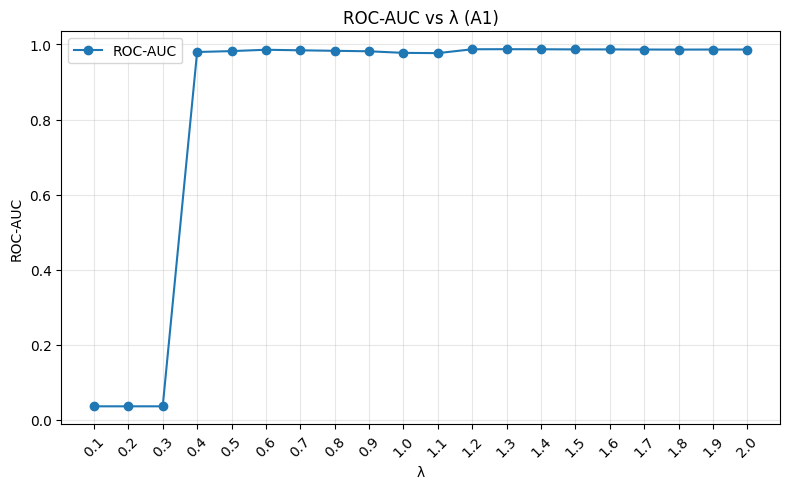

In [ ]:
# لیست λها و مقادیر متناظر ROC-AUC
lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
               0.6, 0.7, 0.8, 0.9, 1.0,
               1.1, 1.2, 1.3, 1.4, 1.5,
               1.6, 1.7, 1.8, 1.9, 2.0]

roc_auc_list = [0.0357, 0.0357, 0.0357, 0.9799, 0.9823,
                0.9859, 0.9844, 0.9831, 0.9818, 0.9776,
                0.9769, 0.9872, 0.9874, 0.9872, 0.9868,
                0.9868, 0.9865, 0.9863, 0.9865, 0.9865]

# رسم نمودار
plt.figure(figsize=(8, 5))
plt.plot(lambda_list, roc_auc_list, marker='o', linestyle='-',
         color='C0', label='ROC-AUC')
plt.title('ROC-AUC vs λ (A1)')
plt.xlabel('λ')
plt.ylabel('ROC-AUC')
plt.xticks(lambda_list, rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## ⚪ 7. Radius Neighborhood for G1

In [ ]:
    n, m = X1.shape
    lammda = 2.0
    delta = np.zeros(m)
    ID = np.all(X1 <= 1, axis=0)
    delta[ID] = np.std(X1[:, ID], axis=0) / lammda

    print(f"Neighborhood radius for each {X1.shape[1]} Features with λ = {lammda} for G1:")
    for idx, d in enumerate(delta, start=1):
        print(f"  Feature : {idx:2d}: δ(Neighborhood radius ) = {d:.6f}")

Neighborhood radius for each 20 Features with λ = 2.0 for G1:
  Feature :  1: δ(Neighborhood radius ) = 0.000000
  Feature :  2: δ(Neighborhood radius ) = 0.102455
  Feature :  3: δ(Neighborhood radius ) = 0.000000
  Feature :  4: δ(Neighborhood radius ) = 0.000000
  Feature :  5: δ(Neighborhood radius ) = 0.071423
  Feature :  6: δ(Neighborhood radius ) = 0.000000
  Feature :  7: δ(Neighborhood radius ) = 0.000000
  Feature :  8: δ(Neighborhood radius ) = 0.188049
  Feature :  9: δ(Neighborhood radius ) = 0.000000
  Feature : 10: δ(Neighborhood radius ) = 0.000000
  Feature : 11: δ(Neighborhood radius ) = 0.184636
  Feature : 12: δ(Neighborhood radius ) = 0.000000
  Feature : 13: δ(Neighborhood radius ) = 0.103085
  Feature : 14: δ(Neighborhood radius ) = 0.000000
  Feature : 15: δ(Neighborhood radius ) = 0.000000
  Feature : 16: δ(Neighborhood radius ) = 0.098027
  Feature : 17: δ(Neighborhood radius ) = 0.000000
  Feature : 18: δ(Neighborhood radius ) = 0.183147
  Feature : 19: δ(Ne

# 🔴 Implement for G2

## ⚪ 2. Extract indices from .csv file

In [19]:
# --- Configuration ---
try:
    # --- Step 1: Load the original (raw) dataset using pandas ---
    # df_original = pd.read_csv(csv_file_path, header=None)
    print(f"Shape of the original dataset: {df_original.shape} (rows, columns)")

    num_cols = df_original.shape[1]

    # For better readability, let's assign names to the columns.
    column_names = [f"c{i}" for i in range(1, num_cols)] + ["label"]
    df_original.columns = column_names

    # --- Step 2: Apply the condition2 to define the G2 subset ---
    condition2 = (df_original['c20'] == 'A201')

    # Create the G2 subset dataframe by applying the filter
    df_g2 = df_original[condition2]

    # --- Step 3: Extract the indices of the rows that satisfy the condition ---
    g2_indices = df_g2.index.to_numpy()

    # --- Step 4" Checking the Number of Outliers in G2 ---
    g2_label_counts = df_g2['label'].value_counts()

    # --- Output and Verification ---
    print(f"Number of samples satisfying the G2 condition: {len(g2_indices)}")

    # Display the number of outliers in G2.
    print(f"Number of outliers in the G2 subset: {g2_label_counts}")

except Exception as e:
    print(f"An unexpected error occurred: {e}")

Shape of the original dataset: (714, 21) (rows, columns)
Number of samples satisfying the G2 condition: 680
Number of outliers in the G2 subset: label
1    667
2     13
Name: count, dtype: int64


## ⚪ 3. Making X_tem from G2 indices italicized text

In [20]:
# Conver a2_indices to python list
X_tem2 = g2_indices.tolist()

## ⚪ 6. Run algorythm for G2

In [21]:
if __name__ == "__main__":

    # 1) Load data
    mat       = loadmat('german_1_14_variant1.mat')
    full_data = mat['trandata']            # shape = (n_samples, 21)

    # 2) Separate features and labels
    X2 = full_data[:, :20]                   # First 20 columns
    y2 =  full_data[:, 20].astype(int)       # Column 21 (index 20)

    # 3) Normalize only the features (columns 1, 4, 7, 10, 12, 15, 17)
    numeric_idx = [1, 4, 7, 10, 12, 15, 17]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X2[:, numeric_idx] = scaler.fit_transform(X2[:, numeric_idx])

    # 4) Run the algorithm with the same X_tem2 and lammda=2.0
    out_scores2 = WNCROD(X2, X_tem2, lammda=2.0)

    # 5) Extract true labels only for X_tem2
    y_true2 = y2[X_tem2]

    # 6) Compute metrics
    roc_auc_G2 = roc_auc_score(y_true2, out_scores2)
    ap_G2      = average_precision_score(y_true2, out_scores2)

    print(f"ROC-AUC: {roc_auc_G2:.4f}")
    print(f"Average Precision (AP): {ap_G2:.4f}")

ROC-AUC: 0.9822
Average Precision (AP): 0.4261


In [ ]:
if __name__ == "__main__":
    # لیست λهایی که می‌خواهید تست کنید
    lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
                   0.6, 0.7, 0.8, 0.9, 1.0,
                   1.1, 1.2, 1.3, 1.4, 1.5,
                   1.6, 1.7, 1.8, 1.9, 2.0]

    # 1) بارگذاری داده
    mat       = loadmat('german_1_14_variant1.mat')
    full_data = mat['trandata']            # شکل: (n_samples, 7)

    # 2) جدا کردن ویژگی‌ها و برچسب‌ها
    X2 = full_data[:, :20]                  # 6 ستون اول
    y2 = full_data[:, 20].astype(int)       # ستون 7 (اندیس 6)

    # 3) Normalize only the features (columns 1, 4, 7, 10, 12, 15)
    numeric_idx = [1, 4, 7, 10, 12, 15]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X2[:, numeric_idx] = scaler.fit_transform(X2[:, numeric_idx])

    # 4) برچسب‌های واقعی برای نمونه‌های X_tem2
    y_true2 = y2[X_tem2]

    # 5) حلقه برای اجرای WNCROD با مقادیر مختلف λ و محاسبه معیارها
    results2 = []
    for lam in lambda_list:
        out_scores2 = WNCROD(X2, X_tem2, lammda=lam)
        roc2 = roc_auc_score(y_true2, out_scores2)
        ap2  = average_precision_score(y_true2, out_scores2)
        results2.append({
            'lambda': lam,
            'ROC-AUC': roc2,
            'AP': ap2
        })

    # 6) نمایش نتایج
    print("نتایج G2 برای λهای مختلف:")
    for r in results2:
        print(f"λ = {r['lambda']:.1f} | ROC-AUC = {r['ROC-AUC']:.4f} | AP = {r['AP']:.4f}")

نتایج G2 برای λهای مختلف:
λ = 0.1 | ROC-AUC = 0.9464 | AP = 0.2682
λ = 0.2 | ROC-AUC = 0.9630 | AP = 0.3153
λ = 0.3 | ROC-AUC = 0.9770 | AP = 0.4022
λ = 0.4 | ROC-AUC = 0.9821 | AP = 0.5432
λ = 0.5 | ROC-AUC = 0.9849 | AP = 0.5373
λ = 0.6 | ROC-AUC = 0.9863 | AP = 0.5331
λ = 0.7 | ROC-AUC = 0.9857 | AP = 0.5218
λ = 0.8 | ROC-AUC = 0.9849 | AP = 0.5196
λ = 0.9 | ROC-AUC = 0.9834 | AP = 0.5024
λ = 1.0 | ROC-AUC = 0.9802 | AP = 0.4908
λ = 1.1 | ROC-AUC = 0.9791 | AP = 0.4941
λ = 1.2 | ROC-AUC = 0.9836 | AP = 0.4280
λ = 1.3 | ROC-AUC = 0.9842 | AP = 0.4488
λ = 1.4 | ROC-AUC = 0.9842 | AP = 0.4488
λ = 1.5 | ROC-AUC = 0.9832 | AP = 0.4256
λ = 1.6 | ROC-AUC = 0.9829 | AP = 0.4231
λ = 1.7 | ROC-AUC = 0.9830 | AP = 0.4304
λ = 1.8 | ROC-AUC = 0.9830 | AP = 0.4304
λ = 1.9 | ROC-AUC = 0.9832 | AP = 0.4317
λ = 2.0 | ROC-AUC = 0.9822 | AP = 0.4261


## ⚪ 7. Radius Neighborhood for G2

In [ ]:
    n, m = X2.shape
    lammda = 2.0
    delta = np.zeros(m)
    ID = np.all(X2 <= 1, axis=0)
    delta[ID] = np.std(X2[:, ID], axis=0) / lammda

    print(f"Neighborhood radius for each {X2.shape[1]} Features with λ = {lammda} for G2:")
    for idx, d in enumerate(delta, start=1):
        print(f"  Feature : {idx:2d}: δ(Neighborhood radius ) = {d:.6f}")

Neighborhood radius for each 20 Features with λ = 2.0 for G2:
  Feature :  1: δ(Neighborhood radius ) = 0.000000
  Feature :  2: δ(Neighborhood radius ) = 0.102455
  Feature :  3: δ(Neighborhood radius ) = 0.000000
  Feature :  4: δ(Neighborhood radius ) = 0.000000
  Feature :  5: δ(Neighborhood radius ) = 0.071423
  Feature :  6: δ(Neighborhood radius ) = 0.000000
  Feature :  7: δ(Neighborhood radius ) = 0.000000
  Feature :  8: δ(Neighborhood radius ) = 0.188049
  Feature :  9: δ(Neighborhood radius ) = 0.000000
  Feature : 10: δ(Neighborhood radius ) = 0.000000
  Feature : 11: δ(Neighborhood radius ) = 0.184636
  Feature : 12: δ(Neighborhood radius ) = 0.000000
  Feature : 13: δ(Neighborhood radius ) = 0.103085
  Feature : 14: δ(Neighborhood radius ) = 0.000000
  Feature : 15: δ(Neighborhood radius ) = 0.000000
  Feature : 16: δ(Neighborhood radius ) = 0.098027
  Feature : 17: δ(Neighborhood radius ) = 0.000000
  Feature : 18: δ(Neighborhood radius ) = 0.183147
  Feature : 19: δ(Ne

# 🔴 Implement for G3

## ⚪ 2. Extract indices from .csv file

In [11]:
# --- Configuration ---
try:
    # --- Step 1: Load the original (raw) dataset using pandas ---
    # df_original = pd.read_csv(csv_file_path, header=None)
    print(f"Shape of the original dataset: {df_original.shape} (rows, columns)")
    num_cols = df_original.shape[1]

    # For better readability, let's assign names to the columns.
    column_names = [f"c{i}" for i in range(1, num_cols)] + ["label"]
    df_original.columns = column_names

    # --- Step 2: Apply the condition3 to define the G3 subset ---
    condition3 = (df_original['c14'] == 'A143')

    # Create the G3 subset dataframe by applying the filter
    df_g3 = df_original[condition3]

    # --- Step 3: Extract the indices of the rows that satisfy the condition ---
    g3_indices = df_g3.index.to_numpy()

    # --- Step 4" Checking the Number of Outliers in G3 ---
    g3_label_counts = df_g3['label'].value_counts()

    # --- Output and Verification ---
    print(f"G3 Condition: Feature 'c6' must be in the range [-1, 1].")
    print(f"Total number of samples in the original dataset: {len(df_original)}")
    print(f"Number of samples satisfying the G3 condition: {len(g3_indices)}")

    # Display the first few indices for a quick check.
    print(f"First 10 indices of the G3 subset: {g3_indices[:10]}")

    # Display the number of outliers in G3.
    print(f"Number of outliers in the G3 subset: {g3_label_counts}")

except Exception as e:
    print(f"An unexpected error occurred: {e}")

Shape of the original dataset: (714, 21) (rows, columns)
G3 Condition: Feature 'c6' must be in the range [-1, 1].
Total number of samples in the original dataset: 714
Number of samples satisfying the G3 condition: 594
First 10 indices of the G3 subset: [0 1 2 3 4 5 6 7 8 9]
Number of outliers in the G3 subset: label
1    590
2      4
Name: count, dtype: int64


## ⚪ 3. Making X_tem from A3 indices italicized text

In [12]:
# Conver g3_indices to python list
X_tem3 = g3_indices.tolist()

## ⚪ 6. Run algorythm for MA3

In [ ]:
if __name__ == "__main__":

    # 1) Load data
    mat       = loadmat('german_1_14_variant1.mat')
    full_data = mat['trandata']            # shape = (n_samples, 21)

    # 2) Separate features and labels
    X3 = full_data[:, :20]                   # First 20 columns
    y3 =  full_data[:, 20].astype(int)       # Column 21 (index 20)

    # 3) Normalize only the features (columns 1, 4, 7, 10, 12, 15)
    numeric_idx = [1, 4, 7, 10, 12, 15]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X3[:, numeric_idx] = scaler.fit_transform(X3[:, numeric_idx])

    # 4) Run the algorithm with the same X_tem3 and lammda=2.0
    out_scores3 = WNCROD(X3, X_tem3, lammda=2.0)

    # 5) Extract true labels only for X_tem3
    y_true3 = y3[X_tem3]

    # 6) Compute metrics
    roc_auc_G3 = roc_auc_score(y_true3, out_scores3)
    ap_G3      = average_precision_score(y_true3, out_scores3)

    print(f"ROC-AUC: {roc_auc_G3:.4f}")
    print(f"Average Precision (AP): {ap_G3:.4f}")

ROC-AUC: 0.9915
Average Precision (AP): 0.3623


In [ ]:

if __name__ == "__main__":
    # 1) مقادیر λ که می‌خواهید تست کنید
    lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
                   0.6, 0.7, 0.8, 0.9, 1.0,
                   1.1, 1.2, 1.3, 1.4, 1.5,
                   1.6, 1.7, 1.8, 1.9, 2.0]

    # 2) بارگذاری داده
    mat       = loadmat('german_1_14_variant1.mat')
    full_data = mat['trandata']            # shape = (n_samples, 21)

    # 3) جدا کردن ویژگی‌ها و برچسب‌ها
    X3 = full_data[:, :20]                  # First 20 columns
    y3 = full_data[:, 20].astype(int)       # Column 21 (index 20)

    # 3) Normalize only the features (columns 1, 4, 7, 10, 12, 15)
    numeric_idx = [1, 4, 7, 10, 12, 15]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X3[:, numeric_idx] = scaler.fit_transform(X3[:, numeric_idx])

    # 6) استخراج برچسب‌های واقعی برای X_tem3
    y_true3 = y3[X_tem3]

    # 7) اجرای حلقه برای همه λها و محاسبهٔ معیارها
    results3 = []
    for lam in lambda_list:
        out_scores3 = WNCROD(X3, X_tem3, lammda=lam)
        roc3 = roc_auc_score(y_true3, out_scores3)
        ap3  = average_precision_score(y_true3, out_scores3)
        results3.append({
            'lambda': lam,
            'ROC-AUC': roc3,
            'AP': ap3
        })

    # 8) نمایش نتایج
    print("نتایج G3 برای λهای مختلف:")
    for r in results3:
        print(f"λ = {r['lambda']:.1f} | ROC-AUC = {r['ROC-AUC']:.4f} | AP = {r['AP']:.4f}")



نتایج G3 برای λهای مختلف:
λ = 0.1 | ROC-AUC = 0.9254 | AP = 0.1988
λ = 0.2 | ROC-AUC = 0.9814 | AP = 0.2527
λ = 0.3 | ROC-AUC = 0.9873 | AP = 0.3252
λ = 0.4 | ROC-AUC = 0.9962 | AP = 0.5012
λ = 0.5 | ROC-AUC = 0.9941 | AP = 0.3946
λ = 0.6 | ROC-AUC = 0.9958 | AP = 0.4929
λ = 0.7 | ROC-AUC = 0.9953 | AP = 0.4512
λ = 0.8 | ROC-AUC = 0.9945 | AP = 0.4194
λ = 0.9 | ROC-AUC = 0.9945 | AP = 0.4194
λ = 1.0 | ROC-AUC = 0.9928 | AP = 0.4048
λ = 1.1 | ROC-AUC = 0.9932 | AP = 0.4298
λ = 1.2 | ROC-AUC = 0.9919 | AP = 0.3381
λ = 1.3 | ROC-AUC = 0.9919 | AP = 0.3381
λ = 1.4 | ROC-AUC = 0.9919 | AP = 0.3381
λ = 1.5 | ROC-AUC = 0.9919 | AP = 0.3381
λ = 1.6 | ROC-AUC = 0.9915 | AP = 0.3290
λ = 1.7 | ROC-AUC = 0.9919 | AP = 0.3394
λ = 1.8 | ROC-AUC = 0.9919 | AP = 0.3394
λ = 1.9 | ROC-AUC = 0.9919 | AP = 0.3394
λ = 2.0 | ROC-AUC = 0.9915 | AP = 0.3623


# 🟢 Final plot

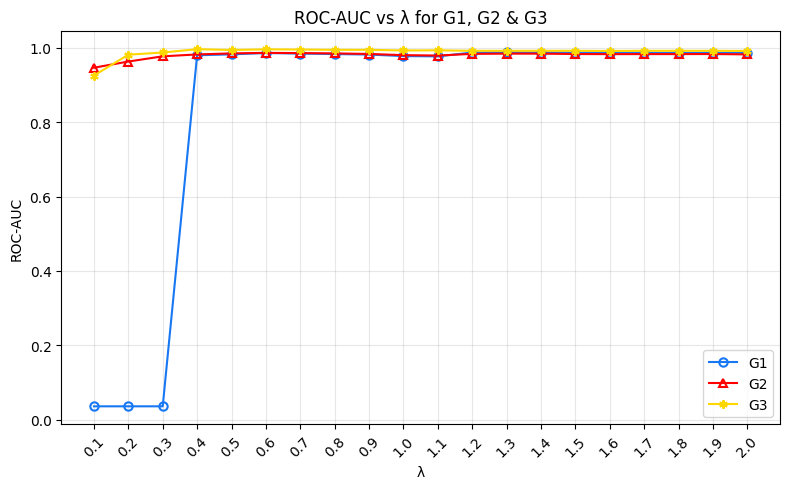

In [ ]:
# بازه مشترک λ برای هر سه A
lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
               0.6, 0.7, 0.8, 0.9, 1.0,
               1.1, 1.2, 1.3, 1.4, 1.5,
               1.6, 1.7, 1.8, 1.9, 2.0]

# مقادیر ROC-AUC برای هر A
roc_auc_g1 =  [0.0357, 0.0357, 0.0357, 0.9799, 0.9823,
               0.9859, 0.9844, 0.9831, 0.9818, 0.9776,
               0.9769, 0.9872, 0.9874, 0.9872, 0.9868,
               0.9868, 0.9865, 0.9863, 0.9865, 0.9865]

roc_auc_g2 = [0.9464, 0.9630, 0.9770, 0.9821, 0.9849,
              0.9863, 0.9857, 0.9849, 0.9834, 0.9802,
              0.9791, 0.9836, 0.9842, 0.9842, 0.9832,
              0.9829, 0.9830, 0.9830, 0.9832, 0.9822]

roc_auc_g3 = [0.9254, 0.9814, 0.9873, 0.9962, 0.9941,
              0.9958, 0.9953, 0.9945, 0.9945, 0.9928,
              0.9932, 0.9919, 0.9919, 0.9919, 0.9919,
              0.9915, 0.9919, 0.9919, 0.9919, 0.9915]

plt.figure(figsize=(8, 5))

# G1: دایره توخالی
plt.plot(lambda_list, roc_auc_g1,
         color='#1877F2', linestyle='-',
         marker='o', fillstyle='none',
         markeredgecolor='#1877F2', markeredgewidth=1.5,
         label='G1')

# G2: مثلث توخالی
plt.plot(lambda_list, roc_auc_g2,
         color='red', linestyle='-',
         marker='^', fillstyle='none',
         markeredgecolor='red', markeredgewidth=1.5,
         label='G2')

# G3: ستاره 6 پر توخالی (هگزاگرام)
plt.plot(lambda_list, roc_auc_g3,
         color='gold', linestyle='-',
         marker=(6, 2, 0), fillstyle='none',
         markeredgecolor='gold', markeredgewidth=1.5,
         label='G3')

plt.title('ROC-AUC vs λ for G1, G2 & G3')
plt.xlabel('λ')
plt.ylabel('ROC-AUC')
plt.xticks(lambda_list, rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 🔵 New Approach for G1

### 1. Main code of new 3WNCROD

In [13]:
def NEW_WNCROD(data: np.ndarray, X_tem: list[int], lammda_list: list[float]) -> np.ndarray:

    n, m = data.shape
    lammda_arr = np.array(lammda_list, dtype=float)
    if lammda_arr.shape[0] != m:
        raise ValueError(f"The length of lammda_list must be equal to the #features : ({m}).")

    X = np.zeros(n, dtype=int)
    X[X_tem] = 1

    D1 = m / 3
    D2 = m / 2
    D3 = 0.9 * m

    # Calculate independent neighborhood radius for each feature
    delta = np.zeros(m, dtype=float)
    ID = np.all(data <= 1, axis=0)
    stds = np.std(data[:, ID], axis=0)
    delta[ID] = stds / lammda_arr[ID]

    Lower = np.zeros((m, n), dtype=float)
    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        Lower_temp = np.min(np.maximum(1 - RM_tem, np.tile(X, (n, 1))), axis=1)
        Lower[col, :Lower_temp.shape[0]] = Lower_temp

    # IB, NEB, NPB
    IB = np.tile(X, (m, 1)) - Lower
    NEB = np.min(IB, axis=0)
    NPB = IB - np.tile(NEB, (m, 1))

    # Weighting
    n_X = int(np.sum(X))
    weight = np.zeros((n_X, m), dtype=float)
    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        wcol = []
        for i in range(n_X):
            temp1 = RM_tem[X_tem[i], :]
            wtemp = 1 - np.sqrt(np.sum(np.minimum(temp1, X)) / n_X)
            wcol.append(wtemp)
        weight[:, col] = wcol

    # D_tem & NOM
    D_tem = np.zeros((n, n), dtype=int)
    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        D_tem += RM_tem.astype(int)
    NOM = m - D_tem
    X_OM = NOM[np.ix_(X_tem, X_tem)]

    # counting : NEB_num, Lower_num, NPB_num
    NEB_num = np.zeros((n_X, m), dtype=int)
    Lower_num = np.zeros((n_X, m), dtype=int)
    NPB_num = np.zeros((n_X, m), dtype=int)
    for col in range(m):
        tLower = Lower[col, :]
        tNPB   = NPB[col, :]
        for i in range(n_X):
            row_OM = X_OM[i, :]
            NEB_num[i, col]   = np.sum(np.minimum(NEB[X_tem],    row_OM <= D1))
            NPB_num[i, col]   = np.sum(np.minimum(tNPB[X_tem],   row_OM >= D2))
            Lower_num[i, col] = np.sum(np.minimum(tLower[X_tem], row_OM >= D3))

    # calculate MNOF
    NDF = (NEB_num + Lower_num + NPB_num) / n_X
    MNOF = np.mean(NDF * weight, axis=1)
    return MNOF

### 2. runing algo

In [ ]:
# this is for best lammda list for TOP AP
if __name__ == "__main__":

    lammda = [0.1, 0.7, 0.1, 0.1, 0.6, 0.1, 0.1, 1.2, 0.1, 0.1, 0.4, 0.1, 0.6, 0.1, 0.1, 0.6, 0.1, 0.4, 0.1, 0.1]

    # 1) Load data
    mat       = loadmat('german_1_14_variant1.mat')
    full_data = mat['trandata']            # shape = (n_samples, 21)

    # 2) Separate features and labels
    X11 = full_data[:, :20]                   # First 20 columns
    y11 =  full_data[:, 20].astype(int)       # Column 21 (index 20)

    # 3) Normalize only the features (columns 1, 4, 7, 10, 12, 15, 17)
    numeric_idx = [1, 4, 7, 10, 12, 15, 17]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X11[:, numeric_idx] = scaler.fit_transform(X11[:, numeric_idx])

    # 4) Run the algorithm with the same X_tem and lammda=0.5
    out_scores11 = NEW_WNCROD(X11, X_tem1, lammda)

    # 5) Extract true labels only for X_tem
    y_true11 = y11[X_tem1]

    # 6) Compute metrics
    roc_auc11 = roc_auc_score(y_true11, out_scores11)
    ap11      = average_precision_score(y_true11, out_scores11)

    print(f"ROC-AUC: {roc_auc11:.4f}")
    print(f"Average Precision (AP): {ap11:.4f}")

ROC-AUC: 0.9887
Average Precision (AP): 0.5701


In [ ]:
# this is for best lammda list for TOP ROC-AUC
if __name__ == "__main__":

    lammda = [0.1, 0.4, 0.1, 0.1, 0.3, 0.1, 0.1, 0.4, 0.1, 0.1, 1.2, 0.1, 0.6, 0.1, 0.1, 0.6, 0.1, 0.4, 0.1, 0.1]

    # 1) Load data
    mat       = loadmat('german_1_14_variant1.mat')
    full_data = mat['trandata']            # shape = (n_samples, 21)

    # 2) Separate features and labels
    X11 = full_data[:, :20]                   # First 20 columns
    y11 =  full_data[:, 20].astype(int)       # Column 21 (index 20)

    # 3) Normalize only the features (columns 1, 4, 7, 10, 12, 15, 17)
    numeric_idx = [1, 4, 7, 10, 12, 15, 17]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X11[:, numeric_idx] = scaler.fit_transform(X11[:, numeric_idx])

    # 4) Run the algorithm with the same X_tem and lammda=0.5
    out_scores11 = NEW_WNCROD(X11, X_tem1, lammda)

    # 5) Extract true labels only for X_tem
    y_true11 = y11[X_tem1]

    # 6) Compute metrics
    roc_auc11 = roc_auc_score(y_true11, out_scores11)
    ap11      = average_precision_score(y_true11, out_scores11)

    print(f"ROC-AUC: {roc_auc11:.4f}")
    print(f"Average Precision (AP): {ap11:.4f}")

ROC-AUC: 0.9891
Average Precision (AP): 0.5578


> 👉👉 **Its ok and it works. we claimed the same result for same lammda.** ✅
>
> **Now we will loking for improvments by searching for best lammda list. 👇👇👇**

### 3. Greedy Search fo lammda's **(1 Candidate List)**

In [ ]:
def greedy_search_lambdas(X: np.ndarray,
                          y: np.ndarray,
                          X_tem: list[int],
                          candidates: list[float],
                          metric_name: str = 'AP'):

    m = X.shape[1]
    # Start with all λ's equal to 1
    best_lambdas = np.ones(m, dtype=float)
    metric_matrix = np.zeros((m, len(candidates)), dtype=float)
    y_true = y[X_tem1]

    # Selecting the criterion function
    if metric_name.upper() == 'AP':
        metric_func = average_precision_score
    elif metric_name.upper() == 'ROC':
        metric_func = roc_auc_score
    else:
        raise ValueError("metric_name must be 'AP' or 'ROC'")

    # Loop over each feature
    for j in range(m):
        best_val = -np.inf
        best_c = best_lambdas[j]
        for idx_c, c in enumerate(candidates):
            # Set λ_j = c and other λs constant
            best_lambdas[j] = c
            # Calculate output score
            scores = NEW_WNCROD(X, X_tem, best_lambdas)
            # Calculation of criteria
            val = metric_func(y_true, scores)
            metric_matrix[j, idx_c] = val
            if val > best_val:
                best_val = val
                best_c = c
        # After testing all candidates for feature j, fix λ_j on the best value
        best_lambdas[j] = best_c

    return best_lambdas, metric_matrix


=== Best Lambdas for AP for G1 ===
[0.1 0.7 0.1 0.1 0.6 0.1 0.1 1.2 0.1 0.1 0.4 0.1 0.6 0.1 0.1 0.6 0.1 0.4
 0.1 0.1]
=== Best Lambdas for ROC-AUC for G1===
[0.1 0.4 0.1 0.1 0.3 0.1 0.1 0.4 0.1 0.1 1.2 0.1 0.6 0.1 0.1 0.6 0.1 0.4
 0.1 0.1]


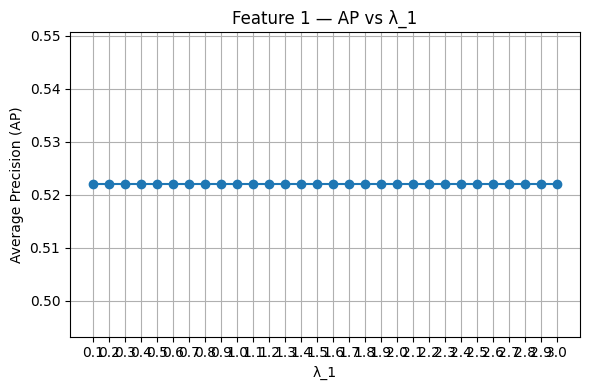

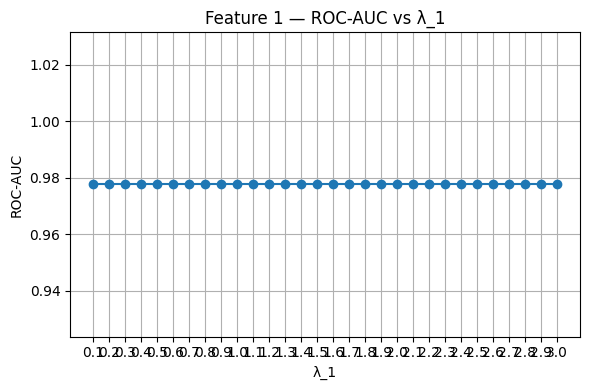

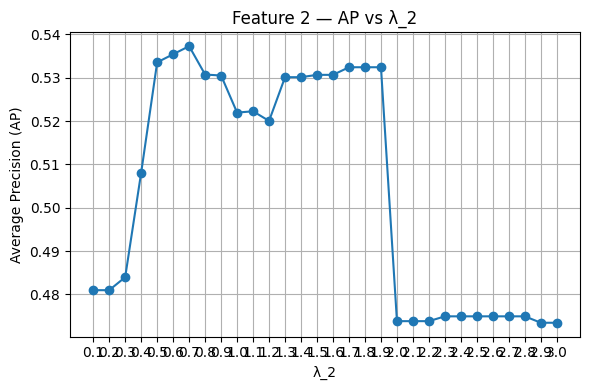

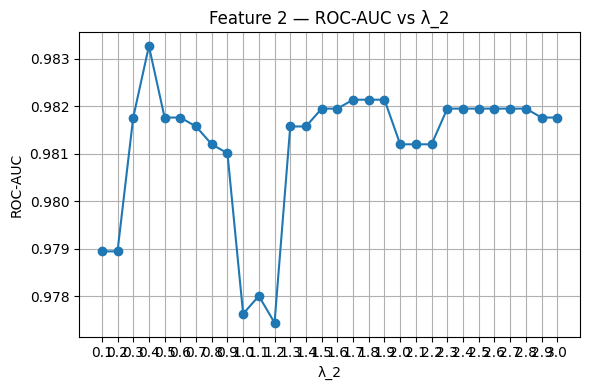

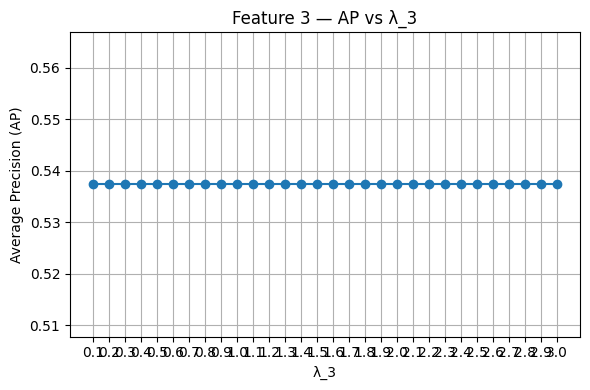

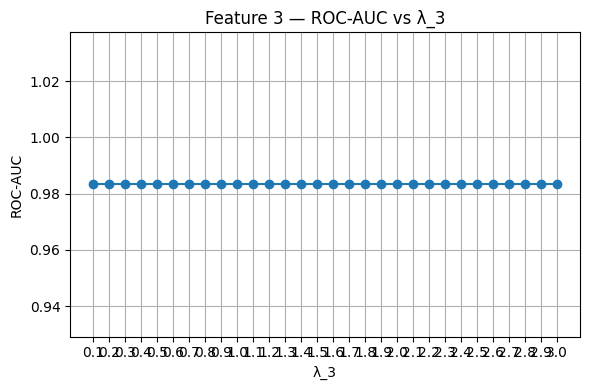

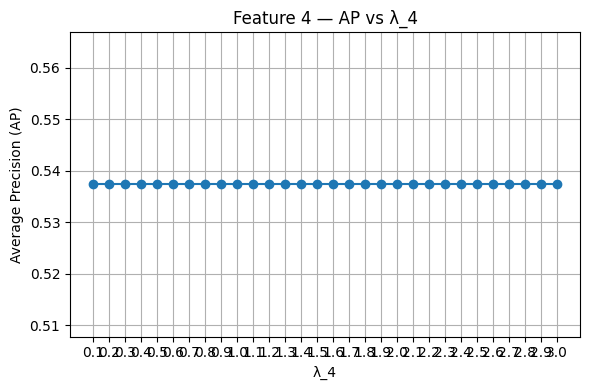

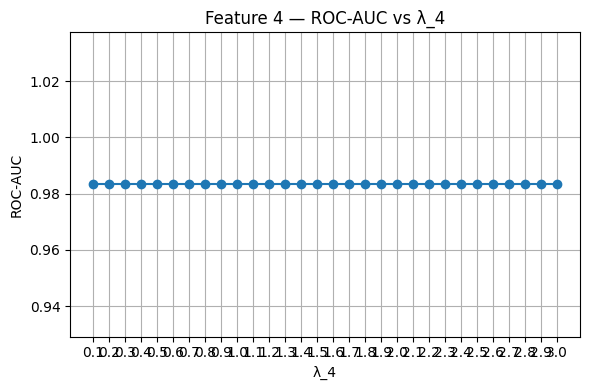

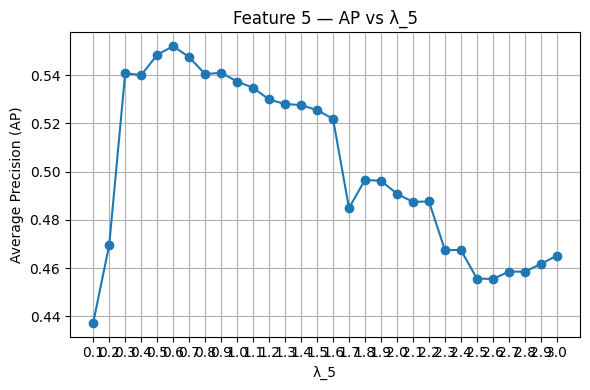

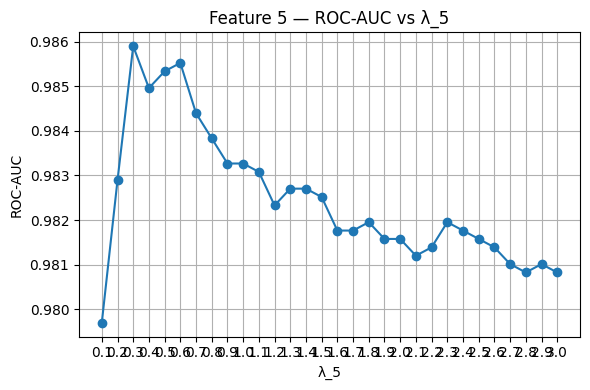

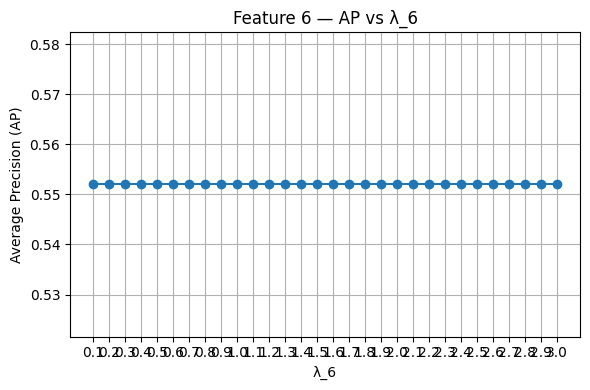

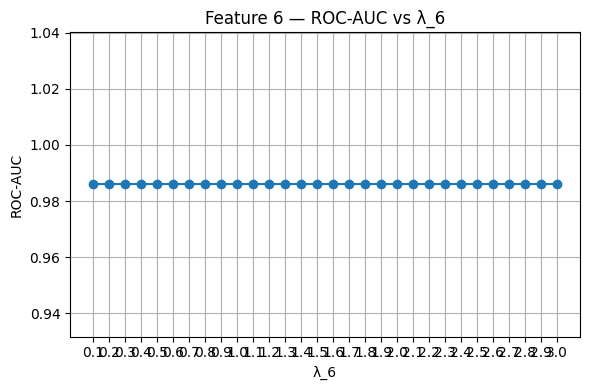

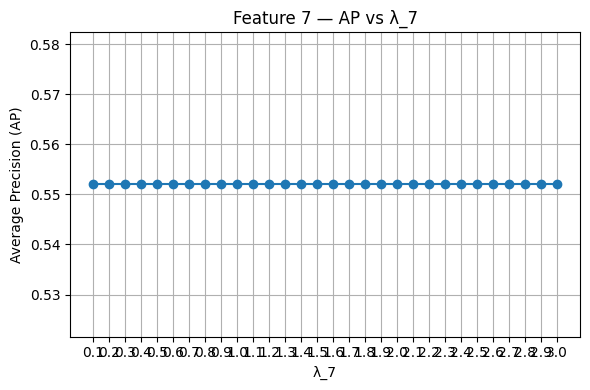

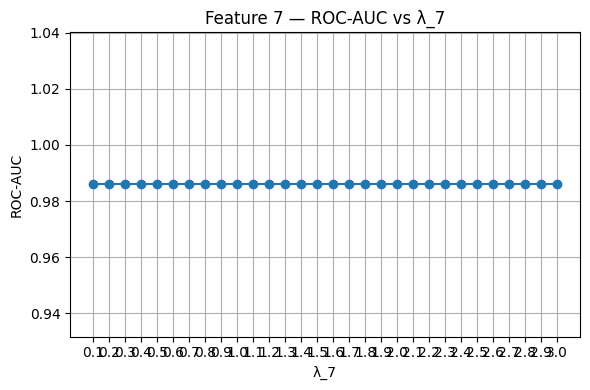

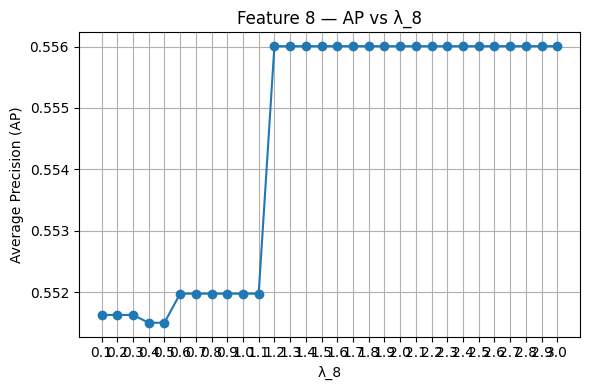

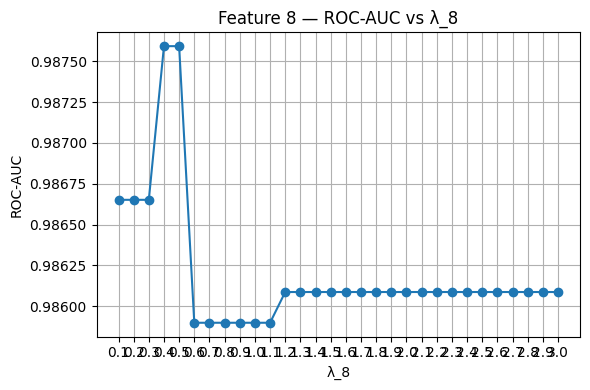

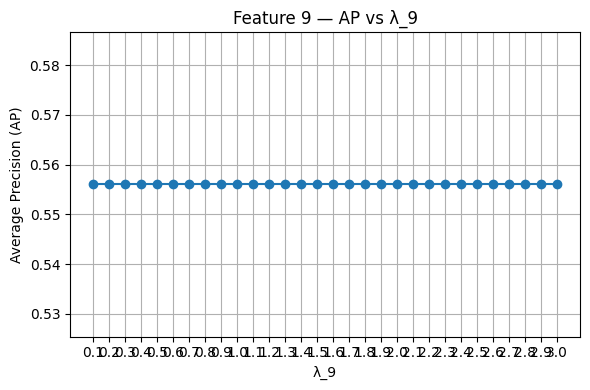

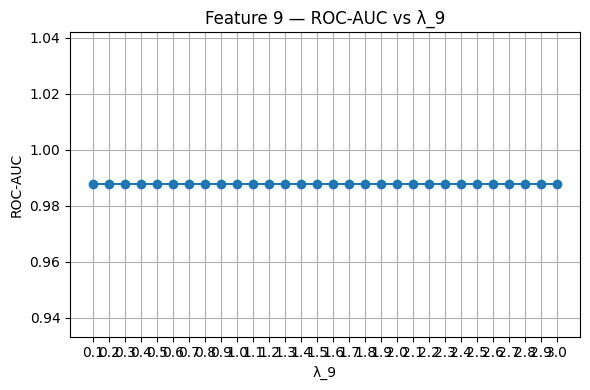

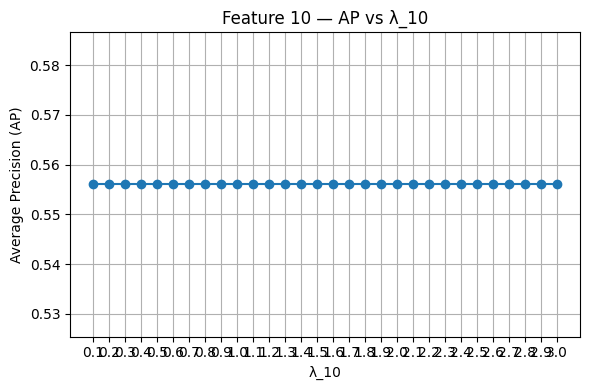

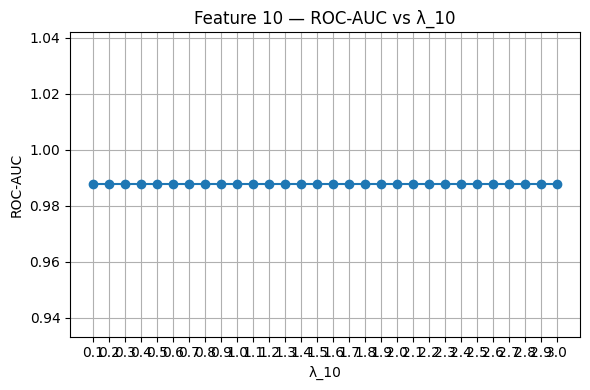

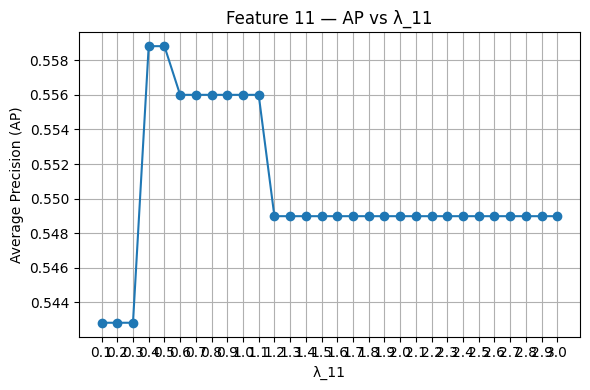

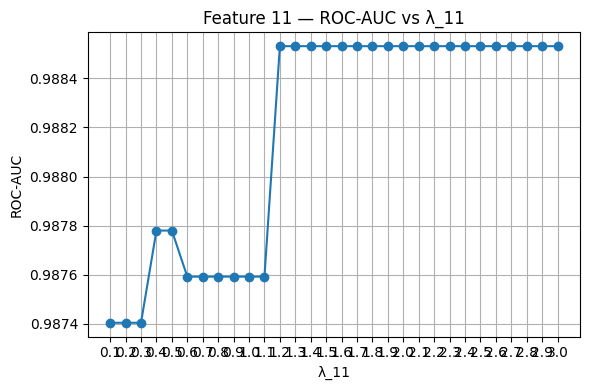

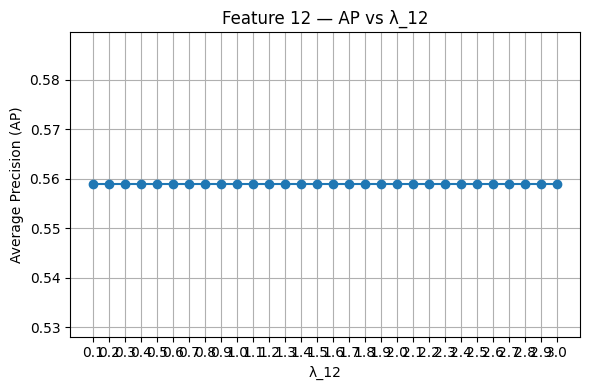

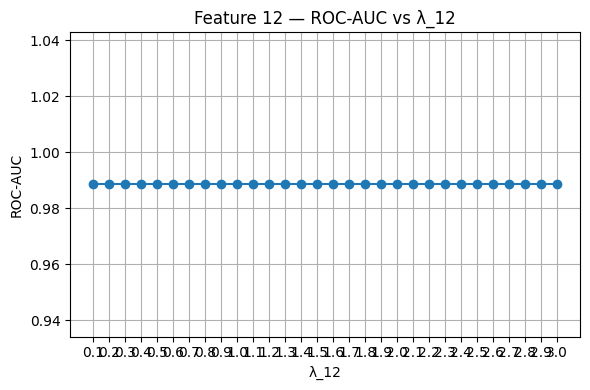

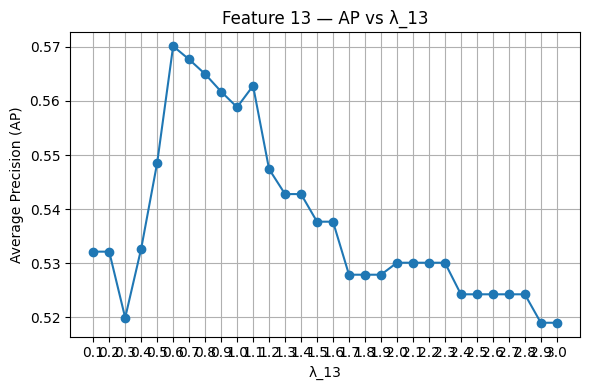

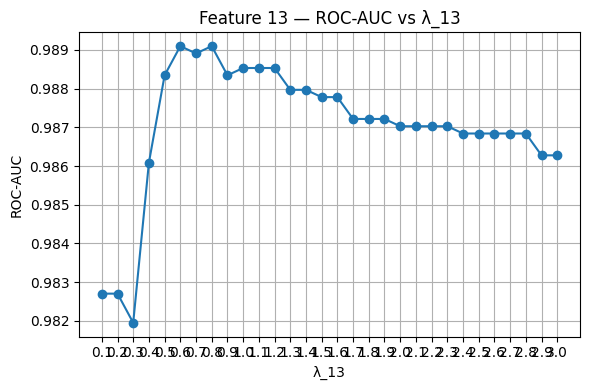

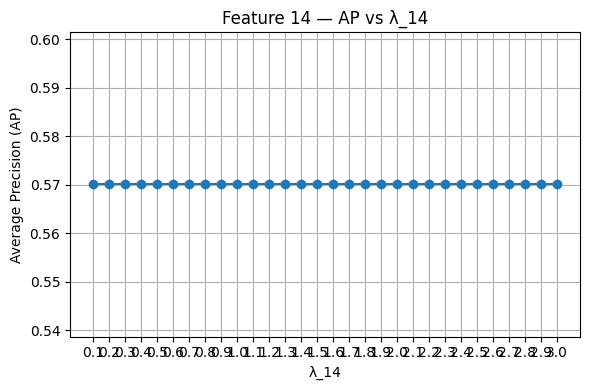

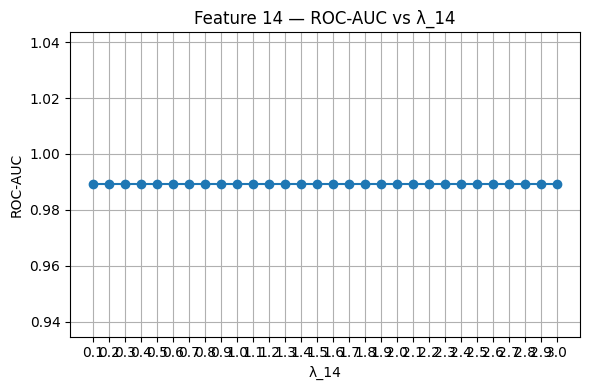

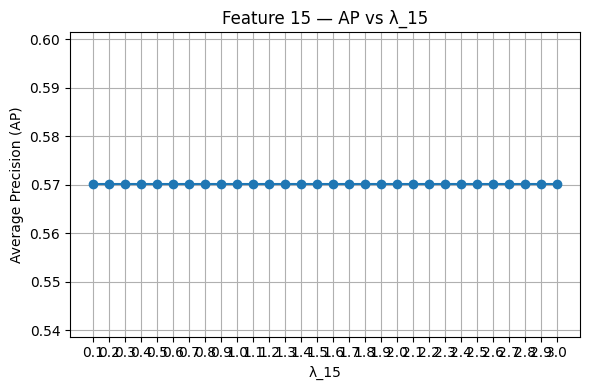

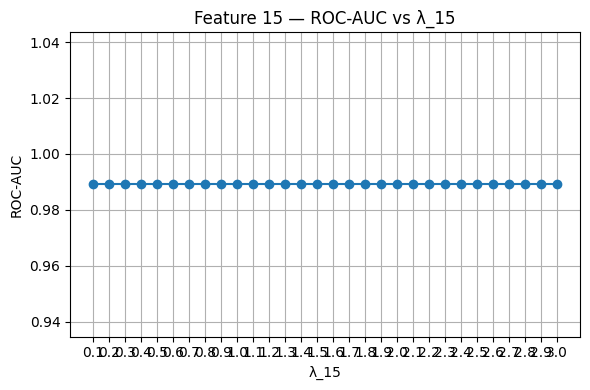

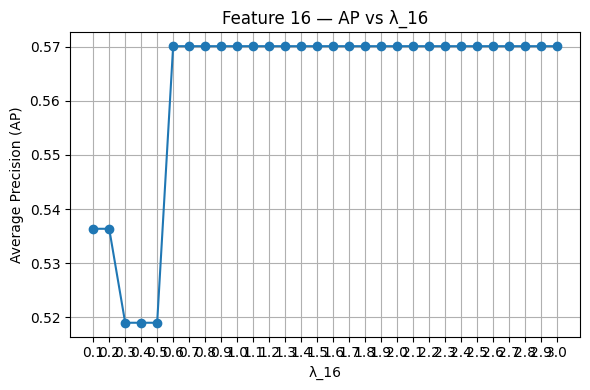

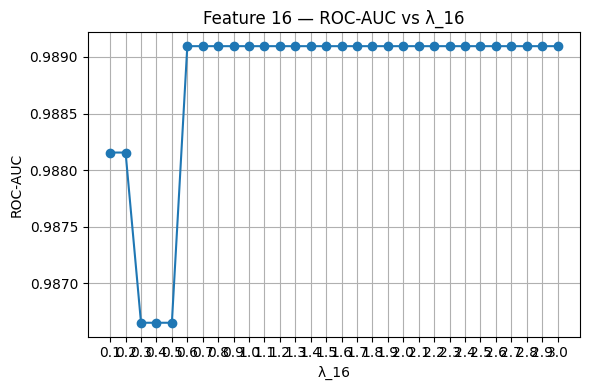

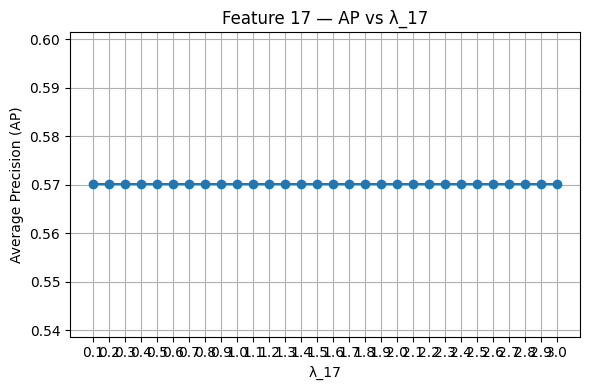

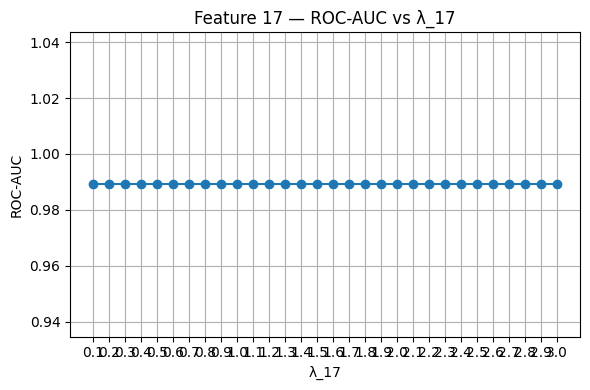

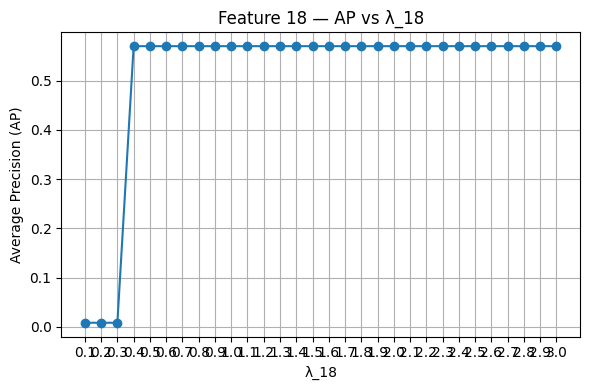

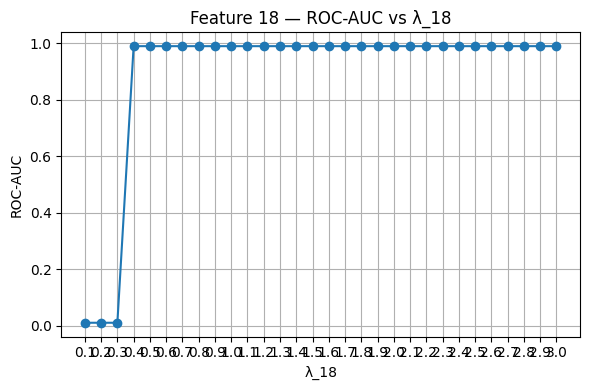

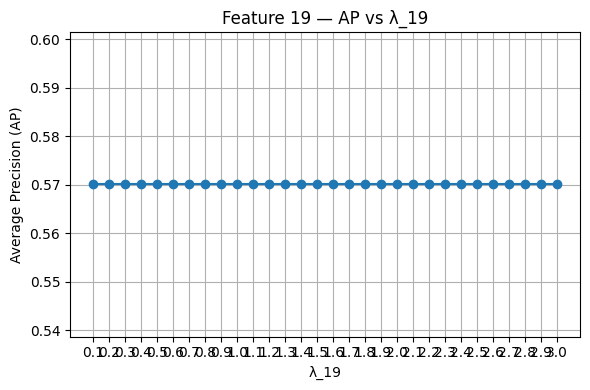

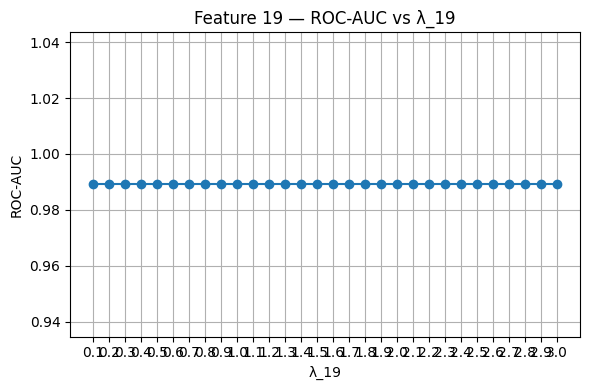

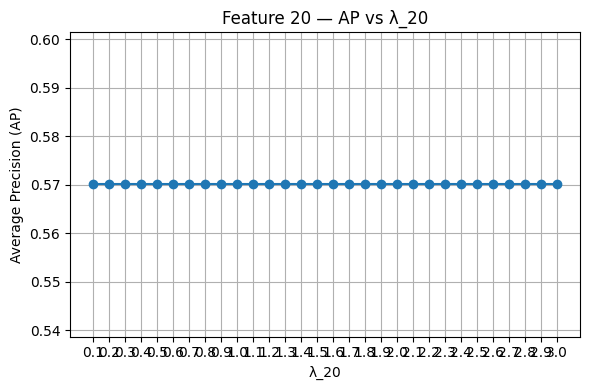

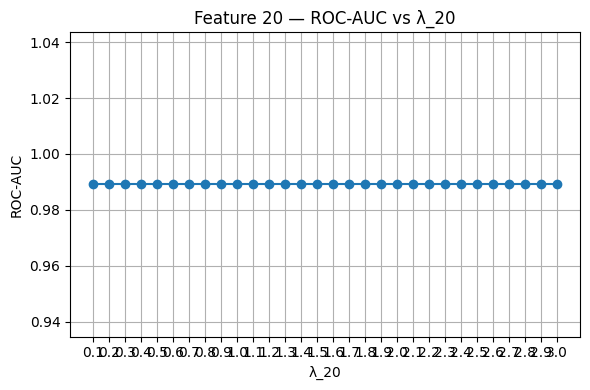

In [ ]:
if __name__ == "__main__":
    # =======================
    #1) Setting the parameters
     # =======================
    candidates = [0.1, 0.2, 0.3, 0.4, 0.5,
                  0.6, 0.7, 0.8, 0.9, 1.0,
                  1.1, 1.2, 1.3, 1.4, 1.5,
                  1.6, 1.7, 1.8, 1.9, 2.0,
                  2.1, 2.2, 2.3, 2.4, 2.5,
                  2.6, 2.7, 2.8, 2.9, 3.0]
    # List of candidate values for λ

    # =======================
    #2) Loading and Preprocessing
    # =======================
    mat = loadmat('german_1_14_variant1.mat')
    full_data = mat['trandata']       # shape = (n_samples, 21)
    X11 = full_data[:, :20]                   # First 20 columns
    y11 =  full_data[:, 20].astype(int)       # Column 21 (index 20)

    # 3) Normalize only the features (columns 1, 4, 7, 10, 12, 15)
    numeric_idx = [1, 4, 7, 10, 12, 15]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X11[:, numeric_idx] = scaler.fit_transform(X11[:, numeric_idx])

    # ================================
    #4) Greedy search for AP
    # ================================
    best_lams_ap, metrics_ap = greedy_search_lambdas(
        X11, y11, X_tem1, candidates, metric_name='AP'
    )
    print("=== Best Lambdas for AP for G1 ===")
    print(best_lams_ap)

    # ================================
    #5) Greedy search for ROC-AUC
    # ================================
    best_lams_roc, metrics_roc = greedy_search_lambdas(
        X11, y11, X_tem1, candidates, metric_name='ROC'
    )
    print("=== Best Lambdas for ROC-AUC for G1===")
    print(best_lams_roc)

    # ============================================
    #6) Draw graphs for each feature and each criterion
    # ============================================
    m = X11.shape[1]
    for j in range(m):
        # Chart for AP
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_ap[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — AP vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("Average Precision (AP)")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

        # Chart for ROC-AUC
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_roc[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — ROC-AUC vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("ROC-AUC")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

# 🔵 New Approach for G2

### 2. runing algo

In [30]:
# Conver g2_indices to python list
X_tem2 = g2_indices.tolist()

In [32]:
# this is for best lammda list for TOP AP & TOP ROC-AUC
if __name__ == "__main__":
    lammda = [0.1, 0.4, 0.1, 0.1, 0.3, 0.1, 0.1, 0.6, 0.1, 0.1, 0.4, 0.1, 0.6, 0.1, 0.1, 0.6, 0.1, 0.4, 0.1, 0.1]

    # 1) Load data
    mat       = loadmat('german_1_14_variant1.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X22 = full_data[:, :20]                   # First 20 columns
    y22 =  full_data[:, 20].astype(int)       # Column 21 (index 20)

    # 3) Normalize only the features (columns 1, 4, 7, 10, 12, 15, 17)
    numeric_idx = [1, 4, 7, 10, 12, 15, 17]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X22[:, numeric_idx] = scaler.fit_transform(X22[:, numeric_idx])

    # 4) Run the algorithm with the same X_tem and lammda
    out_scores22 = NEW_WNCROD(X22, X_tem2, lammda)

    # 5) Extract true labels only for X_tem
    y_true22 = y22[X_tem2]

    # 6) Compute metrics
    roc_auc22 = roc_auc_score(y_true22, out_scores22)
    ap22      = average_precision_score(y_true22, out_scores22)

    print(f"ROC-AUC: {roc_auc22:.4f}")
    print(f"Average Precision (AP): {ap22:.4f}")

ROC-AUC: 0.9899
Average Precision (AP): 0.6190


### 3. Greedy Search fo lammda's **(1 Candidate List)**

In [24]:
def greedy_search_lambdas2(X: np.ndarray,
                          y: np.ndarray,
                          X_tem: list[int],
                          candidates: list[float],
                          metric_name2: str = 'AP'):

    m = X22.shape[1]
    # Start with all λ's equal to 1
    best_lambdas = np.ones(m, dtype=float)
    metric_matrix = np.zeros((m, len(candidates)), dtype=float)
    y_true = y[X_tem2]

    # Selecting the criterion function
    if metric_name2.upper() == 'AP':
        metric_func = average_precision_score
    elif metric_name2.upper() == 'ROC':
        metric_func = roc_auc_score
    else:
        raise ValueError("metric_name2 must be 'AP' or 'ROC'")

    # Loop over each feature
    for j in range(m):
        best_val = -np.inf
        best_c = best_lambdas[j]
        for idx_c, c in enumerate(candidates):
            # Set λ_j = c and other λs constant
            best_lambdas[j] = c
            # Calculate output score
            scores = NEW_WNCROD(X, X_tem, best_lambdas)
            # Calculation of criteria
            val = metric_func(y_true, scores)
            metric_matrix[j, idx_c] = val
            if val > best_val:
                best_val = val
                best_c = c
        # After testing all candidates for feature j, fix λ_j on the best value
        best_lambdas[j] = best_c

    return best_lambdas, metric_matrix

=== Best Lambdas for AP ===
[0.1 0.4 0.1 0.1 0.3 0.1 0.1 0.6 0.1 0.1 0.4 0.1 0.6 0.1 0.1 0.6 0.1 0.4
 0.1 0.1]
=== Best Lambdas for ROC-AUC ===
[0.1 0.4 0.1 0.1 0.3 0.1 0.1 0.6 0.1 0.1 0.4 0.1 0.6 0.1 0.1 0.6 0.1 0.4
 0.1 0.1]


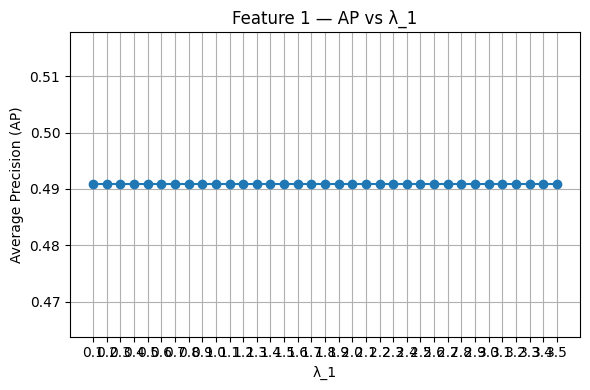

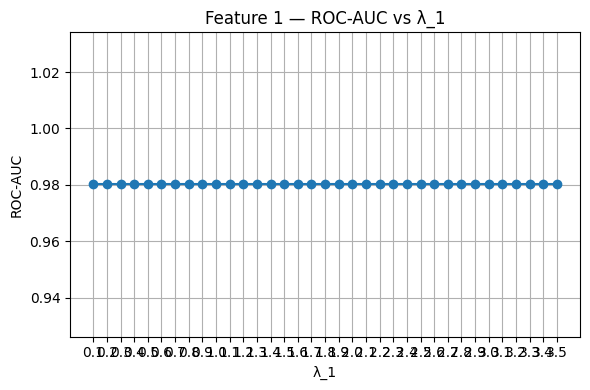

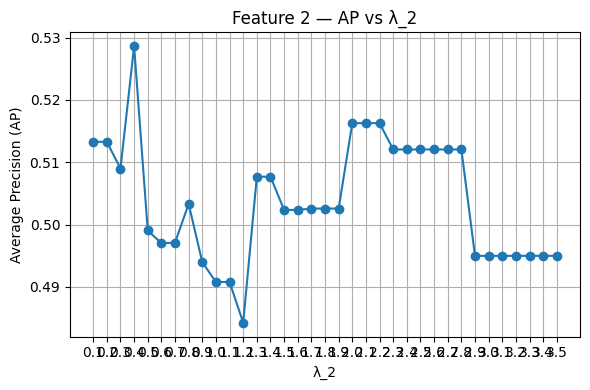

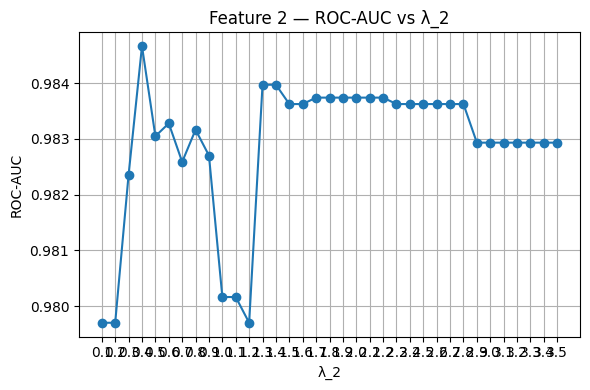

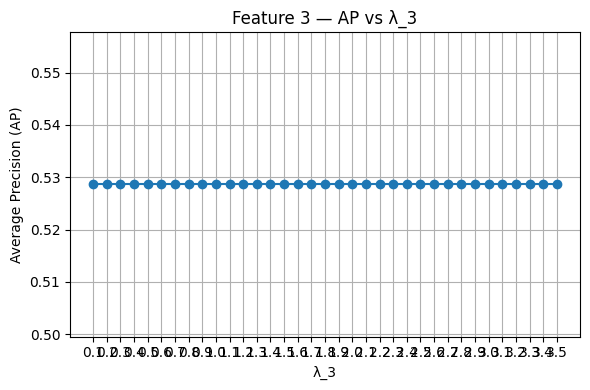

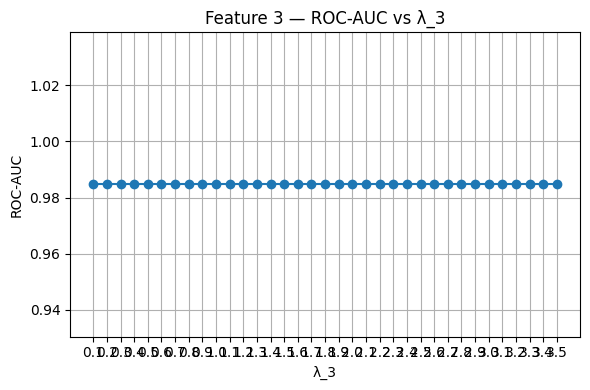

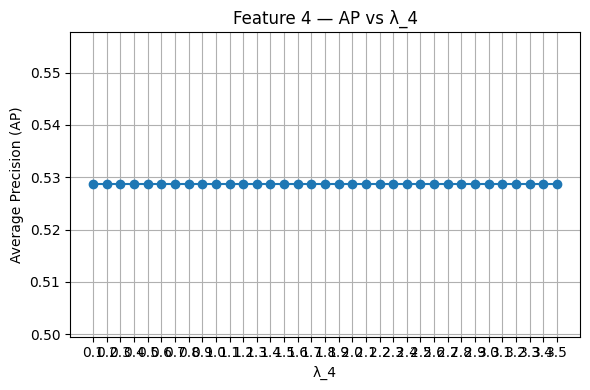

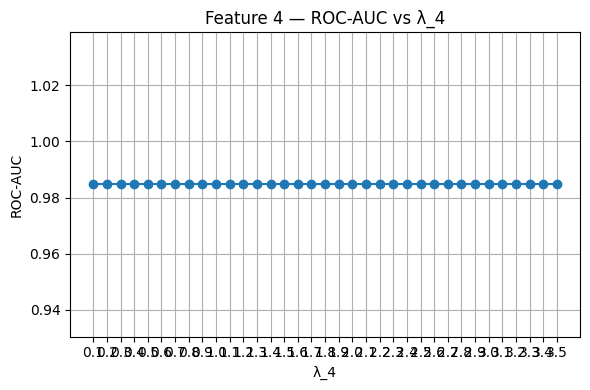

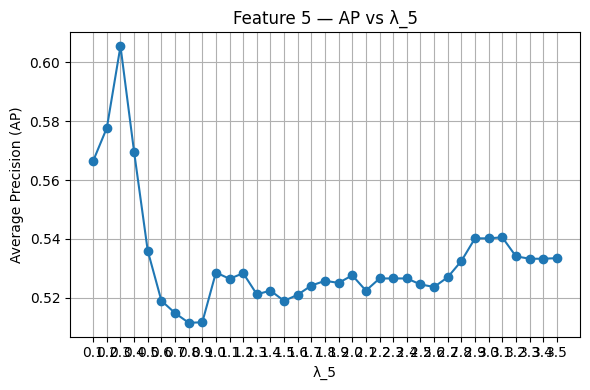

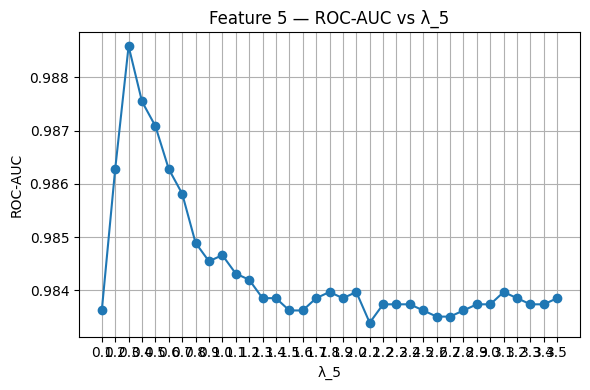

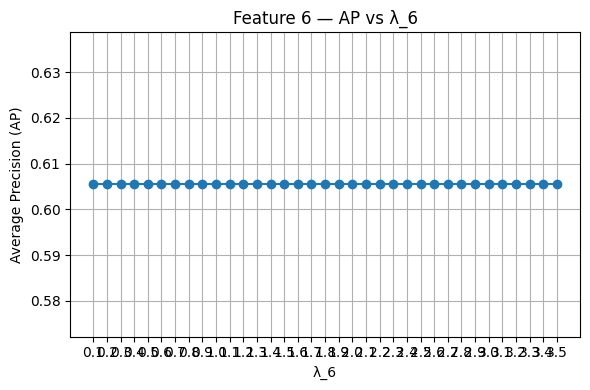

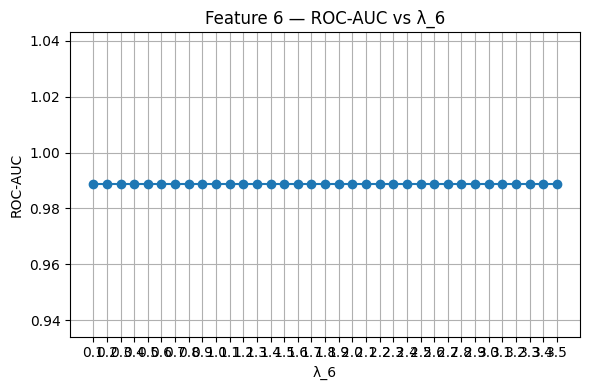

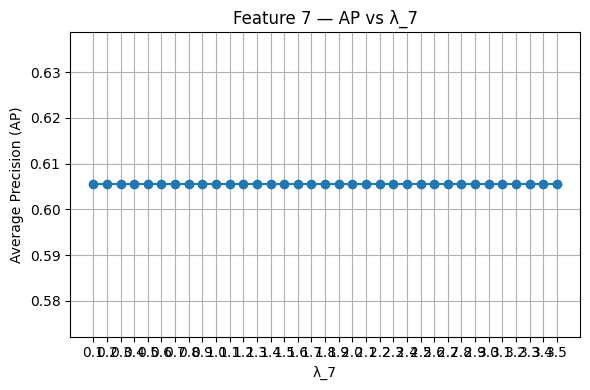

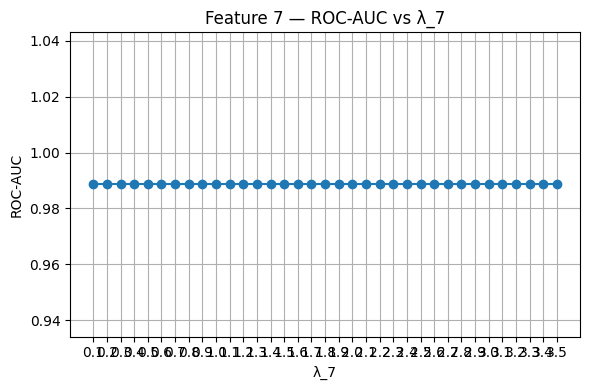

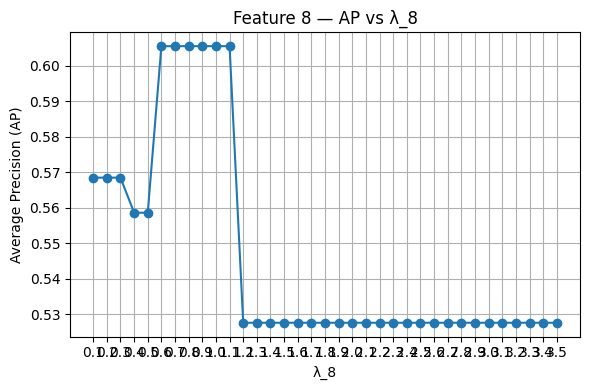

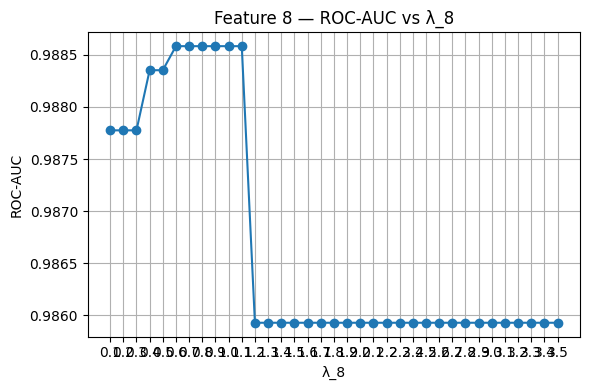

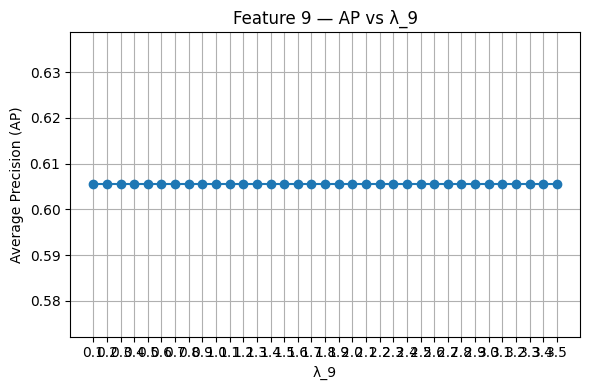

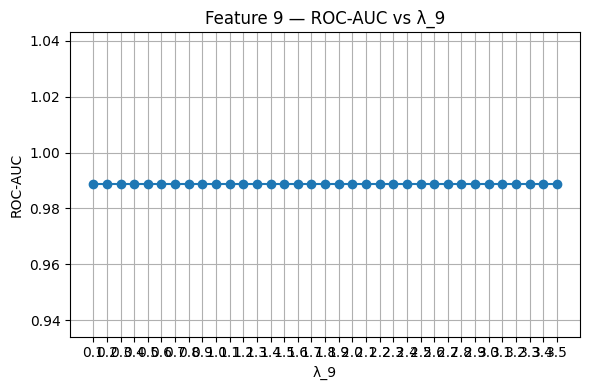

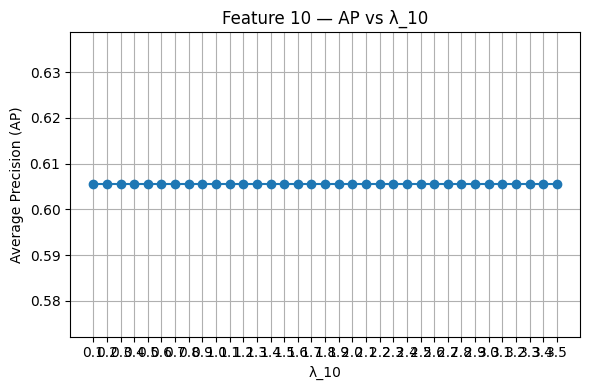

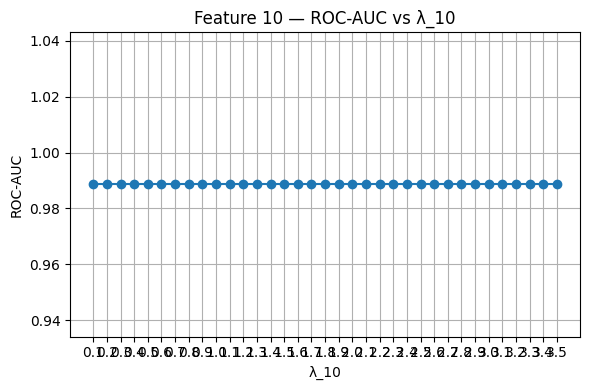

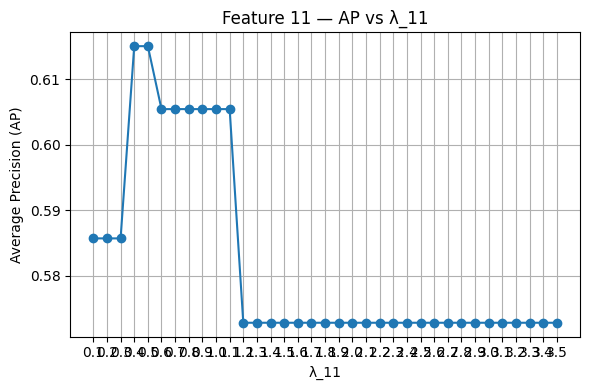

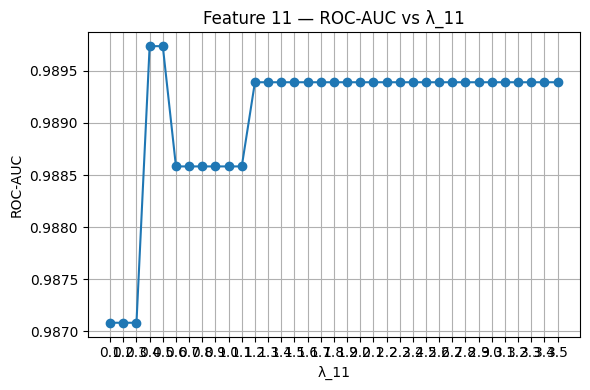

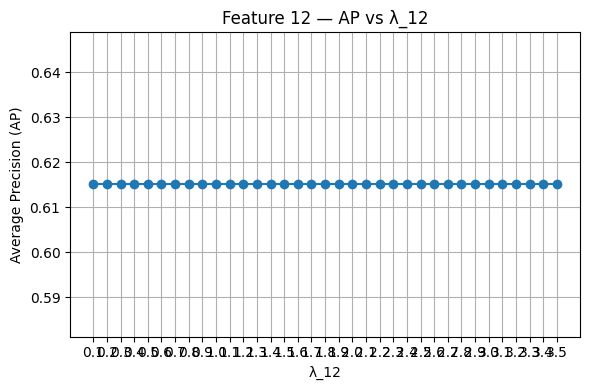

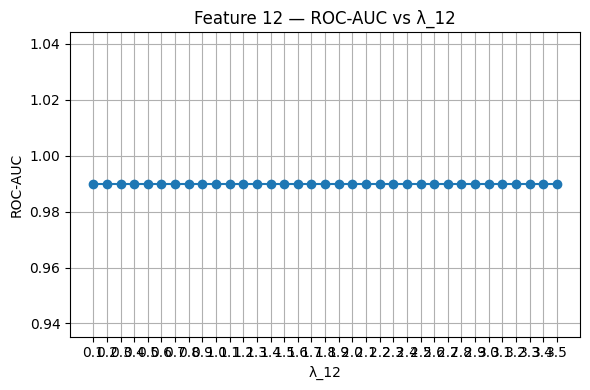

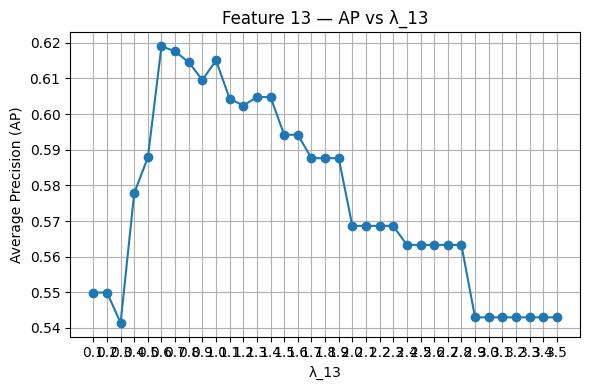

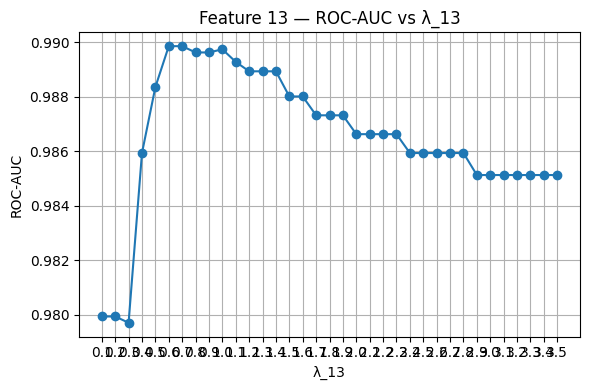

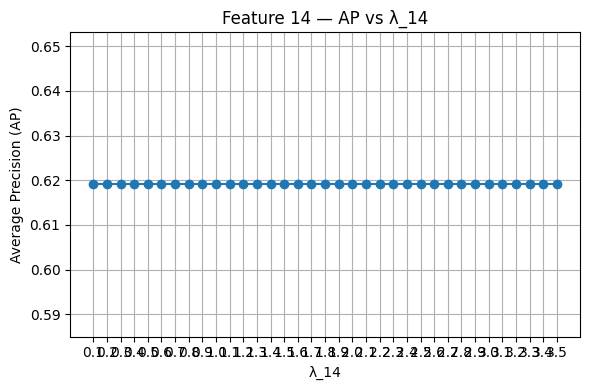

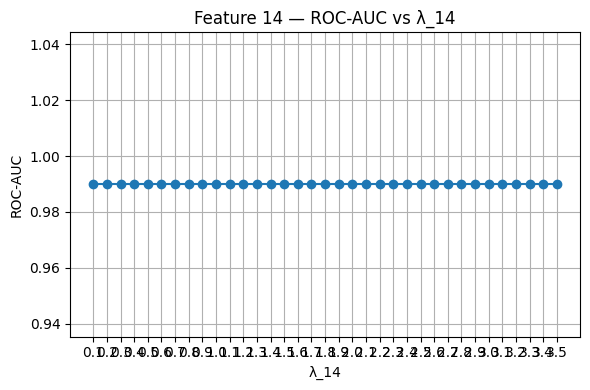

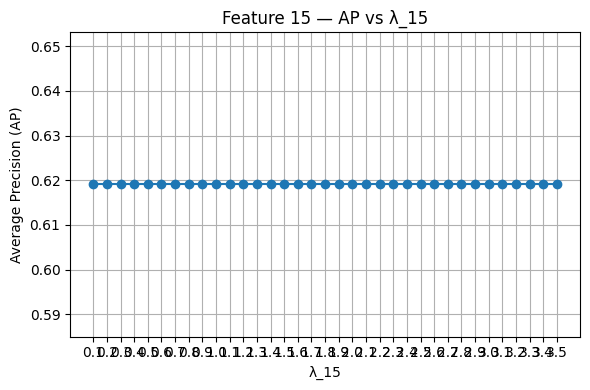

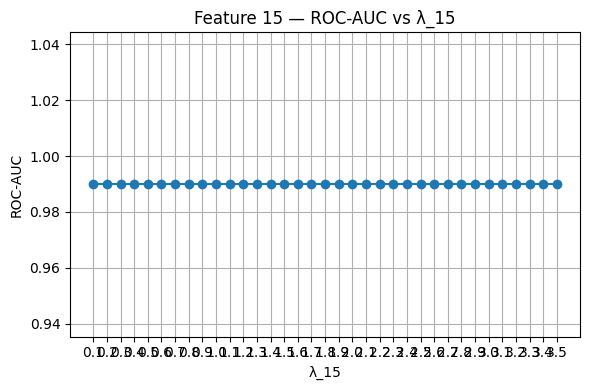

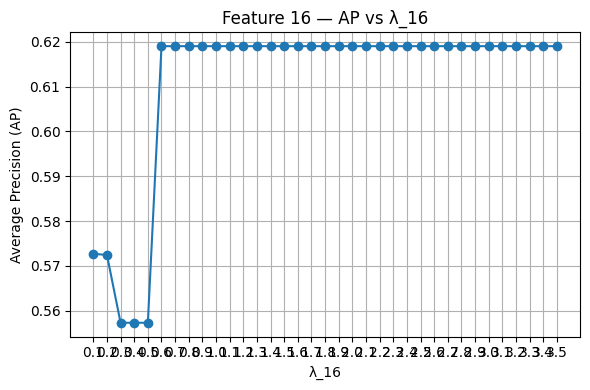

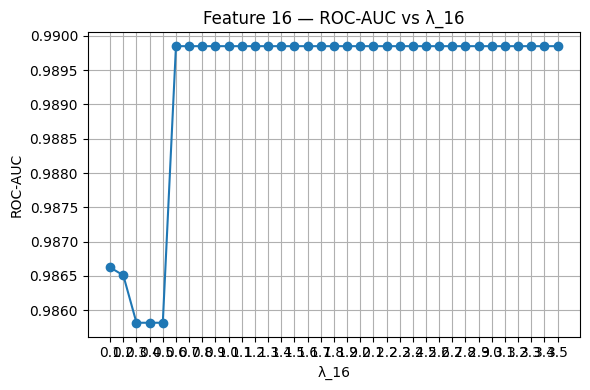

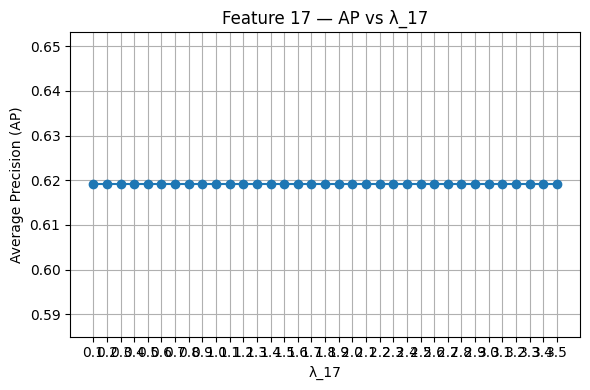

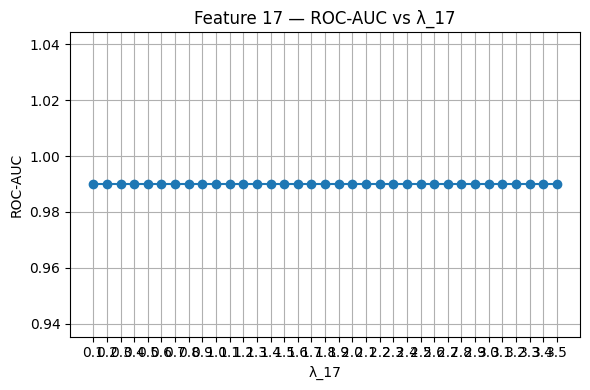

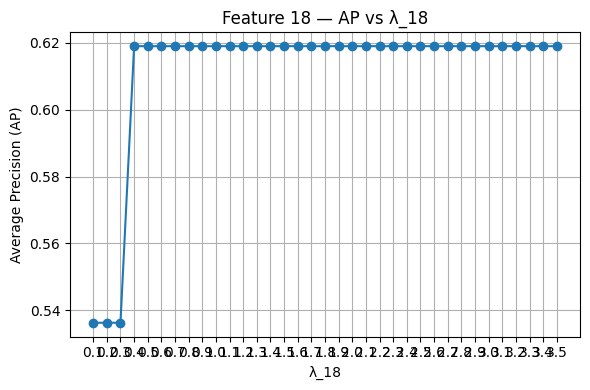

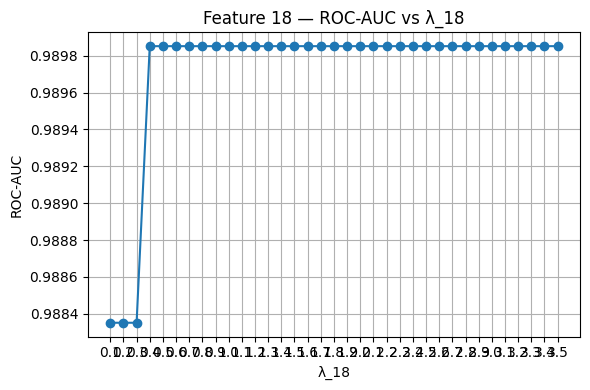

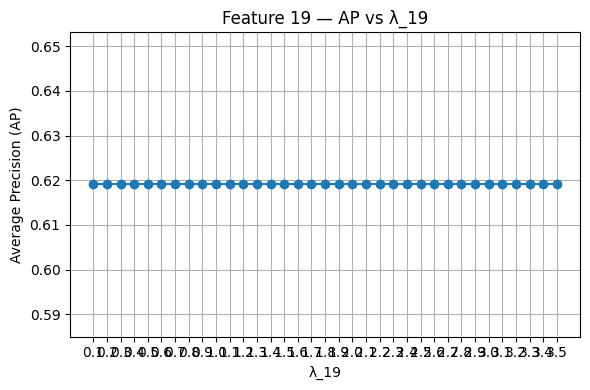

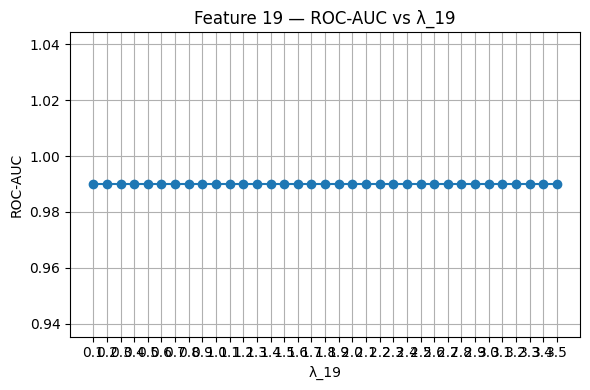

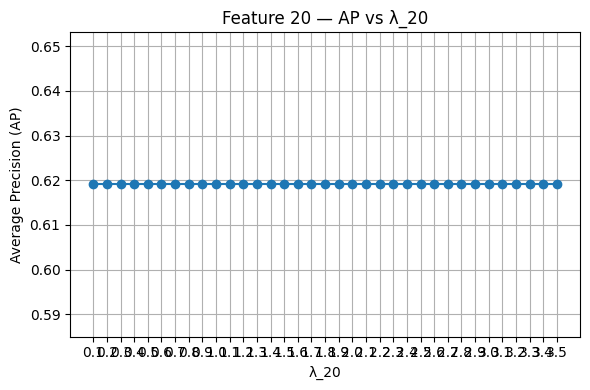

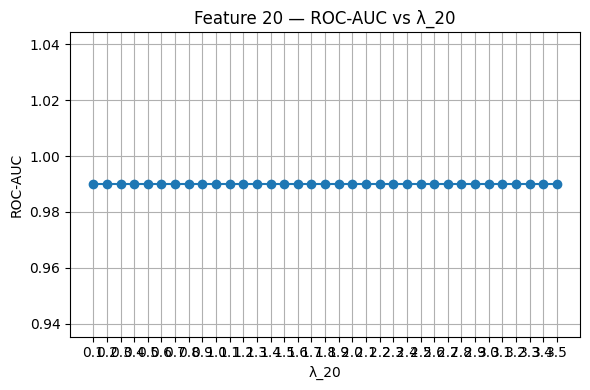

In [25]:
if __name__ == "__main__":
    # =======================
    #1) Setting the parameters
     # =======================

    candidates = [0.1, 0.2, 0.3, 0.4, 0.5,
                  0.6, 0.7, 0.8, 0.9, 1.0,
                  1.1, 1.2, 1.3, 1.4, 1.5,
                  1.6, 1.7, 1.8, 1.9, 2.0,
                  2.1, 2.2, 2.3, 2.4, 2.5,
                  2.6, 2.7, 2.8, 2.9, 3.0,
                  3.1, 3.2, 3.3, 3.4, 3.5]
    # List of candidate values for λ

    # =======================
    #2) Loading and Preprocessing
    # =======================
    mat = loadmat('german_1_14_variant1.mat')
    full_data = mat['trandata']       # shape = (n_samples, 7)
    X22 = full_data[:, :20]                   # First 20 columns
    y22 =  full_data[:, 20].astype(int)       # Column 21 (index 20)

    numeric_idx = [1, 4, 7, 10, 12, 15, 17]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X22[:, numeric_idx] = scaler.fit_transform(X22[:, numeric_idx])

    # ================================
    #3) Greedy search for AP
    # ================================
    best_lams_ap, metrics_ap = greedy_search_lambdas2(
        X22, y22, X_tem2, candidates, metric_name2='AP'
    )
    print("=== Best Lambdas for AP ===")
    print(best_lams_ap)

    # ================================
    #4) Greedy search for ROC-AUC
    # ================================
    best_lams_roc, metrics_roc = greedy_search_lambdas2(
        X22, y22, X_tem2, candidates, metric_name2='ROC'
    )
    print("=== Best Lambdas for ROC-AUC ===")
    print(best_lams_roc)

    # ============================================
    #5) Draw graphs for each feature and each criterion
    # ============================================
    m = X22.shape[1]
    for j in range(m):
        # Chart for AP
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_ap[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — AP vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("Average Precision (AP)")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

        # Chart for ROC-AUC
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_roc[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — ROC-AUC vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("ROC-AUC")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

# 🔵 New Approach for G3

### 2. runing algo

In [26]:
# Conver g3_indices to python list
X_tem3 = g3_indices.tolist()

In [33]:
# this is for best lammda list for TOP AP
if __name__ == "__main__":

    # 1) Load data
    mat       = loadmat('german_1_14_variant1.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    lammda = [0.1, 0.4, 0.1, 0.1, 0.2, 0.1, 0.1, 0.4, 0.1, 0.1, 0.6, 0.1, 2.9, 0.1, 0.1, 0.6, 0.1, 0.4, 0.1, 0.1]

    # 2) Separate features and labels
    X33 = full_data[:, :20]                   # First 20 columns
    y33 =  full_data[:, 20].astype(int)       # Column 21 (index 20)

    # 3) Normalize only the features (columns 1, 4, 7, 10, 12, 15, 17)
    numeric_idx = [1, 4, 7, 10, 12, 15, 17]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X33[:, numeric_idx] = scaler.fit_transform(X33[:, numeric_idx])

    # 4) Run the algorithm with the same X_tem and lammda=0.5
    out_scores33 = NEW_WNCROD(X33, X_tem3, lammda)

    # 5) Extract true labels only for X_tem
    y_true33 = y33[X_tem3]

    # 6) Compute metrics
    roc_auc33 = roc_auc_score(y_true33, out_scores33)
    ap33      = average_precision_score(y_true33, out_scores33)

    print(f"ROC-AUC: {roc_auc33:.4f}")
    print(f"Average Precision (AP): {ap33:.4f}")

ROC-AUC: 0.9970
Average Precision (AP): 0.7153


In [34]:
# this is for best lammda list for TOP ROC
if __name__ == "__main__":

    # 1) Load data
    mat       = loadmat('german_1_14_variant1.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    lammda = [0.1, 0.4, 0.1, 0.1, 0.3, 0.1, 0.1, 1.2, 0.1, 0.1, 0.6, 0.1, 0.1, 0.1, 0.1, 0.3, 0.1, 0.4, 0.1, 0.1]

    # 2) Separate features and labels
    X33 = full_data[:, :20]                   # First 20 columns
    y33 =  full_data[:, 20].astype(int)       # Column 21 (index 20)

    # 3) Normalize only the features (columns 1, 4, 7, 10, 12, 15, 17)
    numeric_idx = [1, 4, 7, 10, 12, 15, 17]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X33[:, numeric_idx] = scaler.fit_transform(X33[:, numeric_idx])
    # 4) Run the algorithm with the same X_tem and lammda=0.5
    out_scores33 = NEW_WNCROD(X33, X_tem3, lammda)

    # 5) Extract true labels only for X_tem
    y_true33 = y33[X_tem3]

    # 6) Compute metrics
    roc_auc33 = roc_auc_score(y_true33, out_scores33)
    ap33      = average_precision_score(y_true33, out_scores33)

    print(f"ROC-AUC: {roc_auc33:.4f}")
    print(f"Average Precision (AP): {ap33:.4f}")

ROC-AUC: 0.9983
Average Precision (AP): 0.6792


### 3. Greedy Search fo lammda's **(1 Candidate List)**

In [28]:
def greedy_search_lambdas3(X33: np.ndarray,
                          y33: np.ndarray,
                          X_tem3: list[int],
                          candidates: list[float],
                          metric_name3: str = 'AP'):

    m = X33.shape[1]
    # Start with all λ's equal to 1
    best_lambdas = np.ones(m, dtype=float)
    metric_matrix = np.zeros((m, len(candidates)), dtype=float)
    y_true3 = y33[X_tem3]

    # Selecting the criterion function
    if metric_name3.upper() == 'AP':
        metric_func = average_precision_score
    elif metric_name3.upper() == 'ROC':
        metric_func = roc_auc_score
    else:
        raise ValueError("metric_name3 must be 'AP' or 'ROC'")

    # Loop over each feature
    for j in range(m):
        best_val = -np.inf
        best_c = best_lambdas[j]
        for idx_c, c in enumerate(candidates):
            # Set λ_j = c and other λs constant
            best_lambdas[j] = c
            # Calculate output score
            scores = NEW_WNCROD(X33, X_tem3, best_lambdas)
            # Calculation of criteria
            val = metric_func(y_true3, scores)
            metric_matrix[j, idx_c] = val
            if val > best_val:
                best_val = val
                best_c = c
        # After testing all candidates for feature j, fix λ_j on the best value
        best_lambdas[j] = best_c

    return best_lambdas, metric_matrix

=== Best Lambdas for AP ===
[0.1 0.4 0.1 0.1 0.2 0.1 0.1 0.4 0.1 0.1 0.6 0.1 2.9 0.1 0.1 0.6 0.1 0.4
 0.1 0.1]
=== Best Lambdas for ROC-AUC ===
[0.1 0.4 0.1 0.1 0.3 0.1 0.1 1.2 0.1 0.1 0.6 0.1 0.1 0.1 0.1 0.3 0.1 0.4
 0.1 0.1]


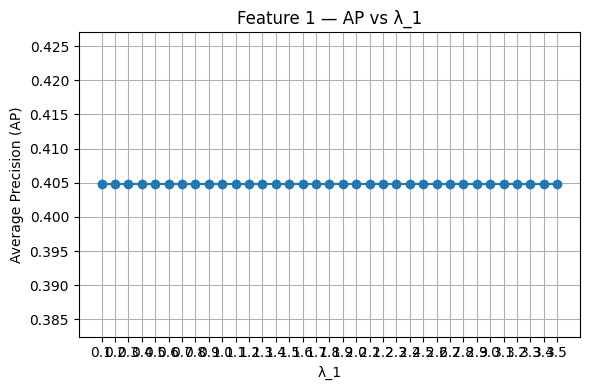

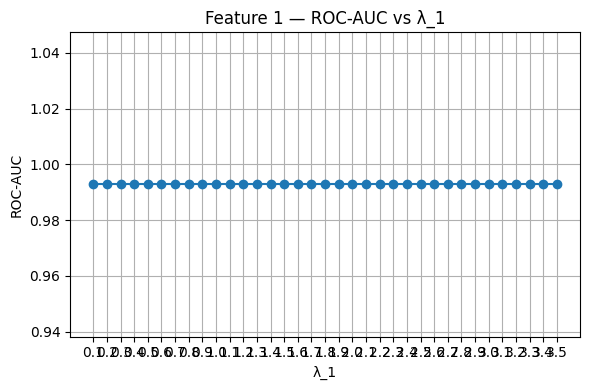

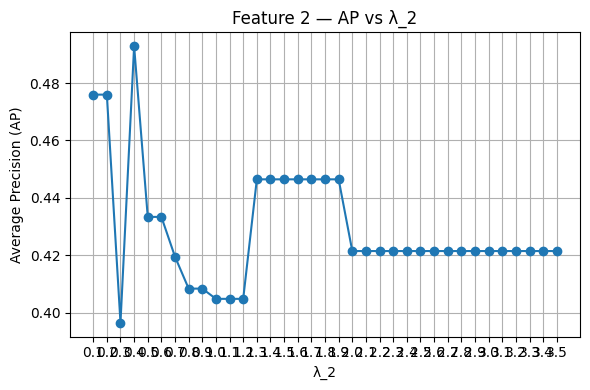

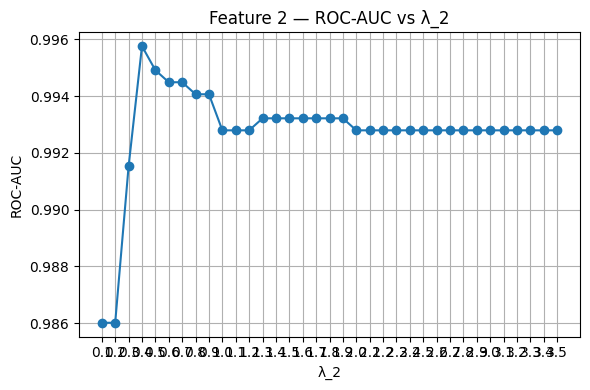

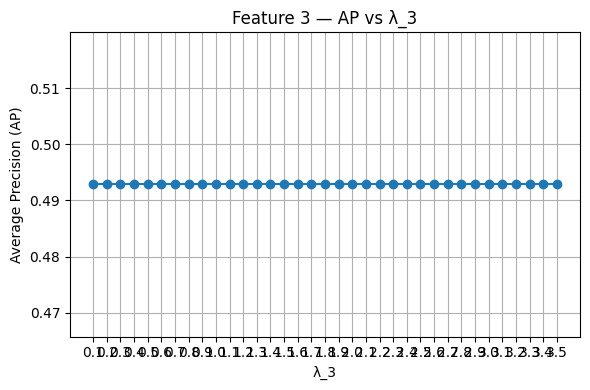

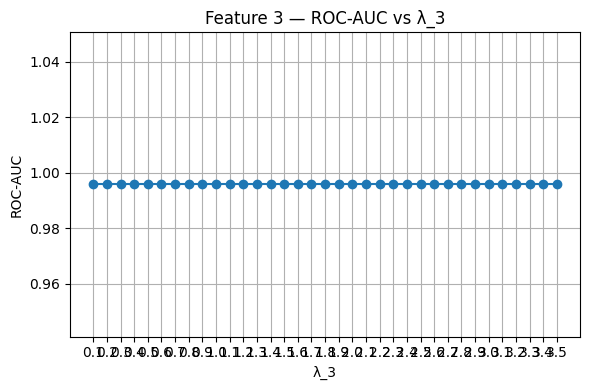

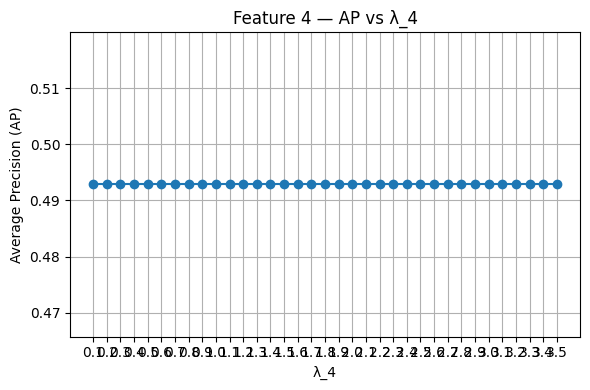

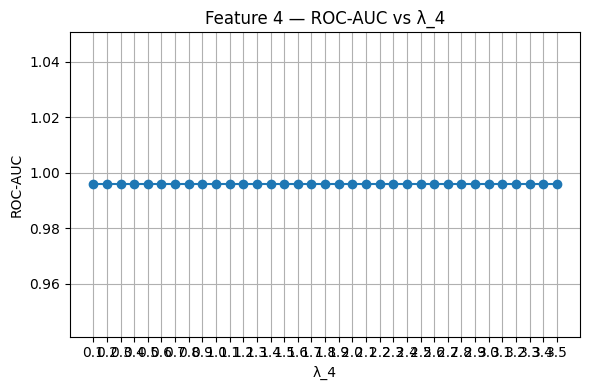

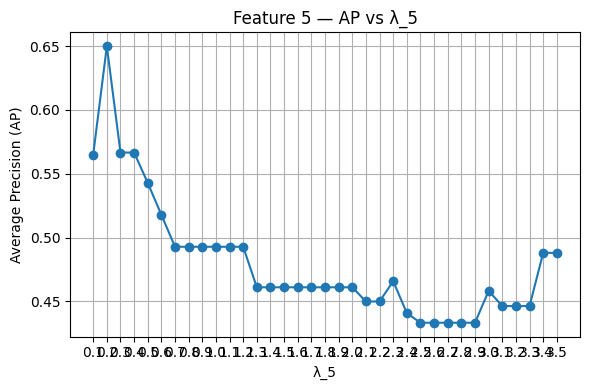

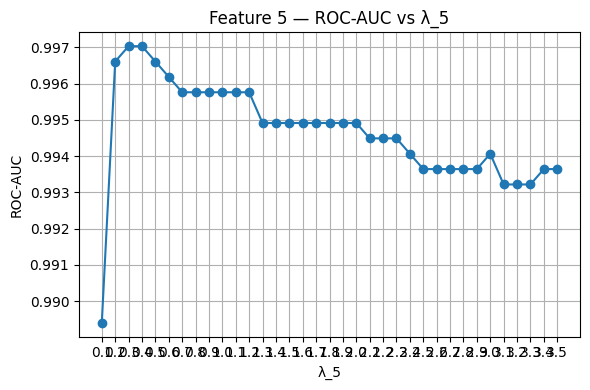

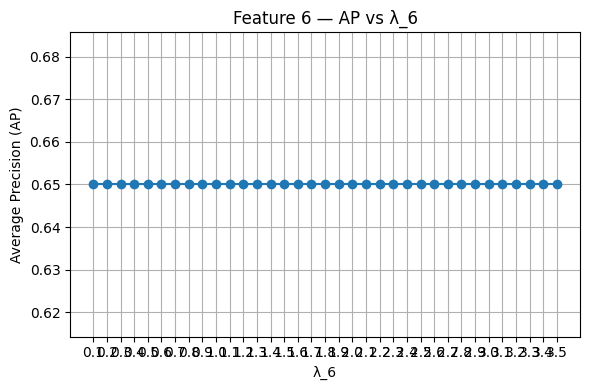

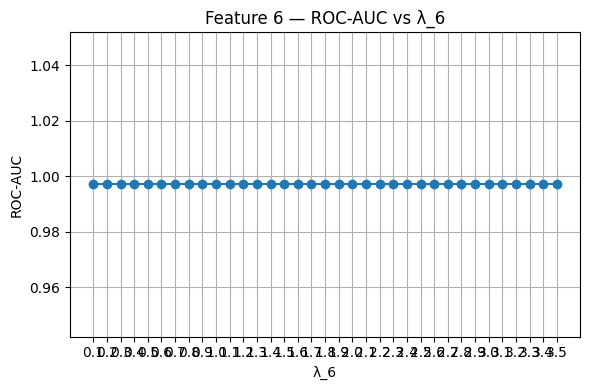

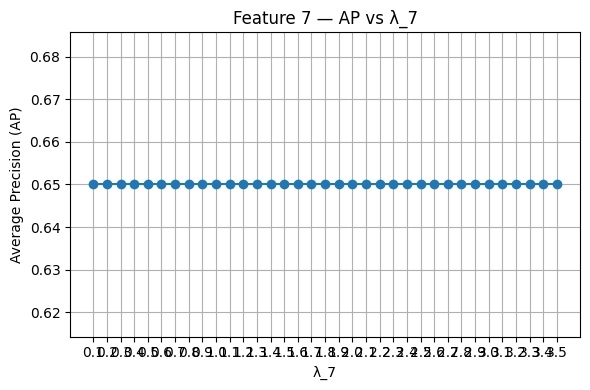

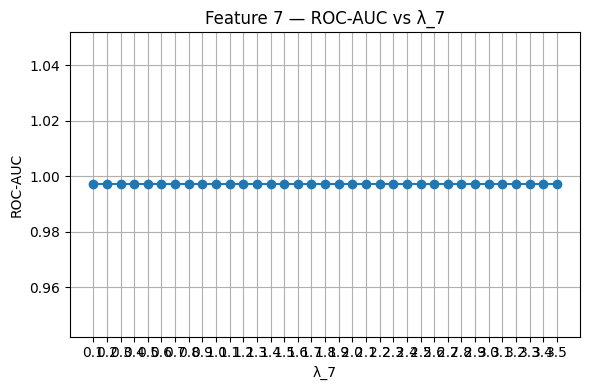

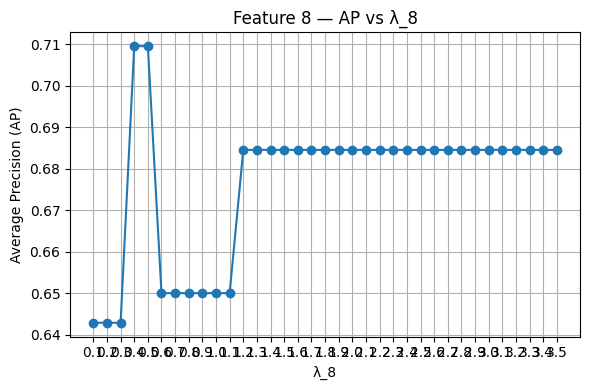

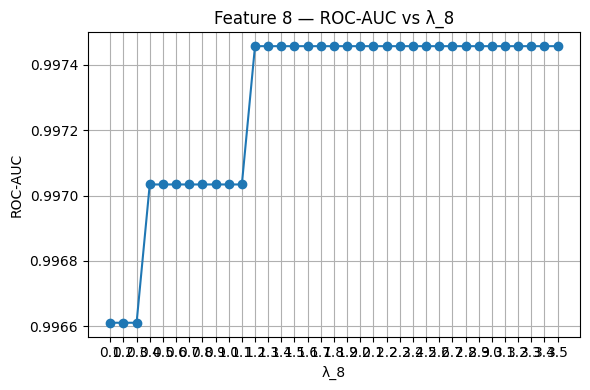

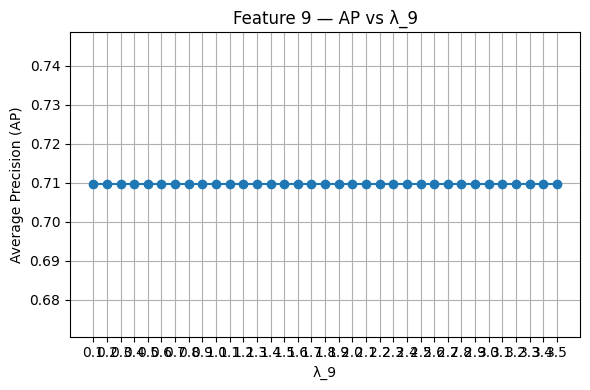

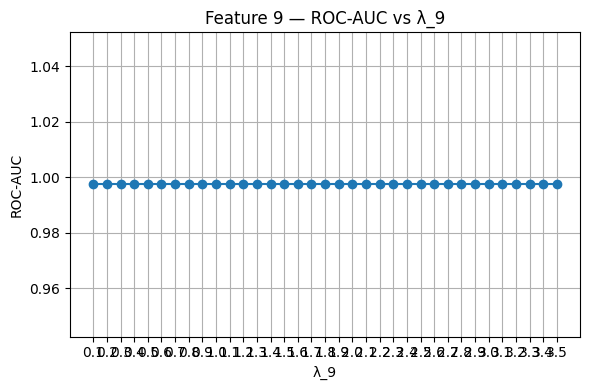

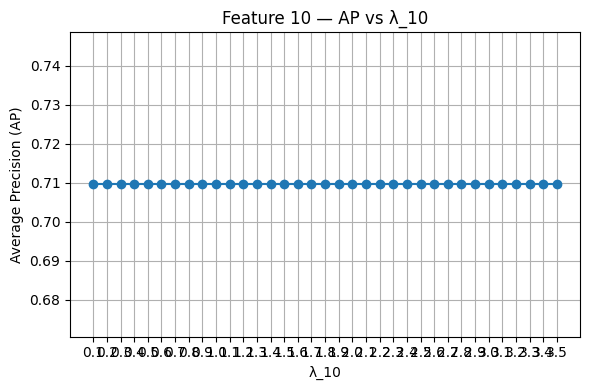

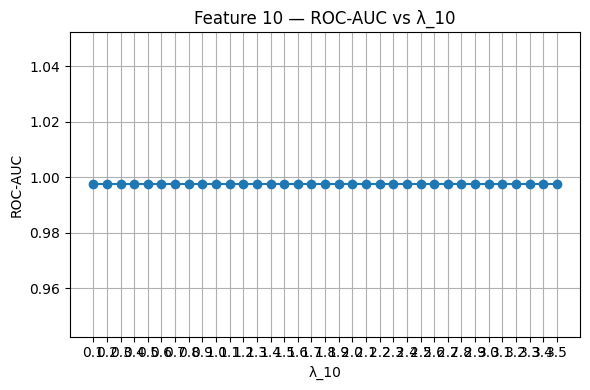

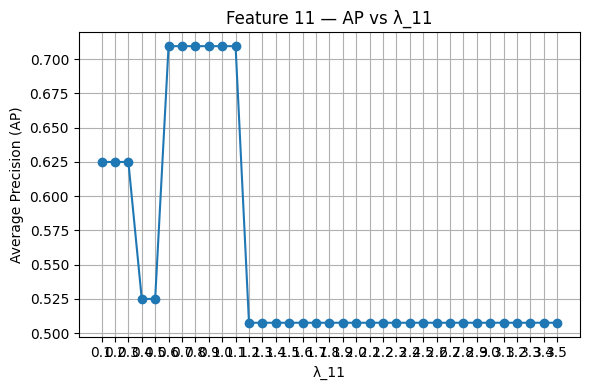

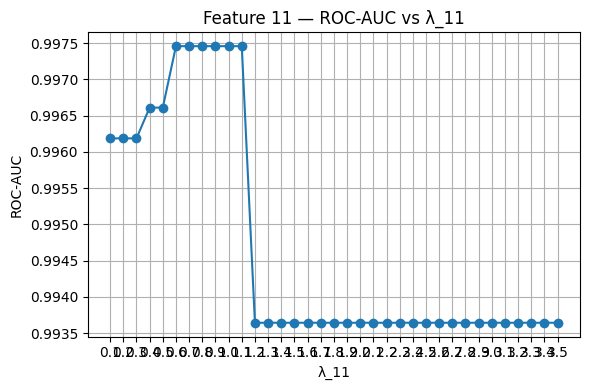

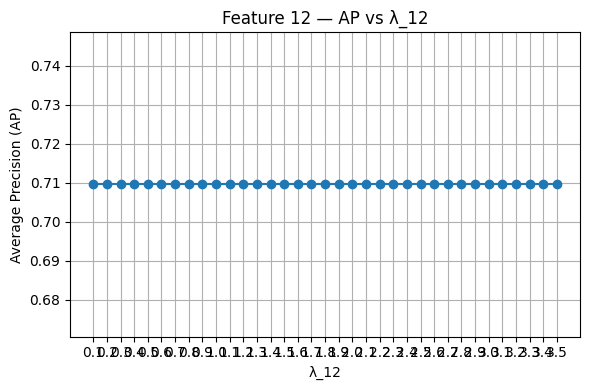

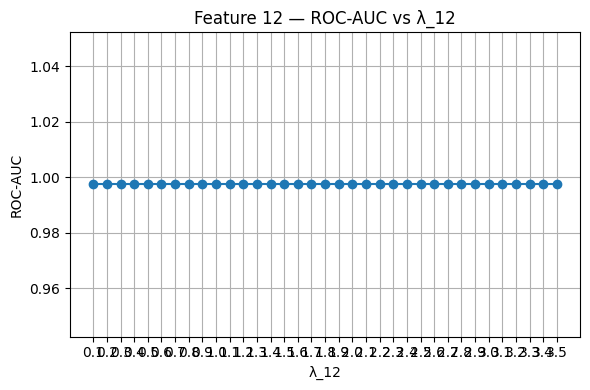

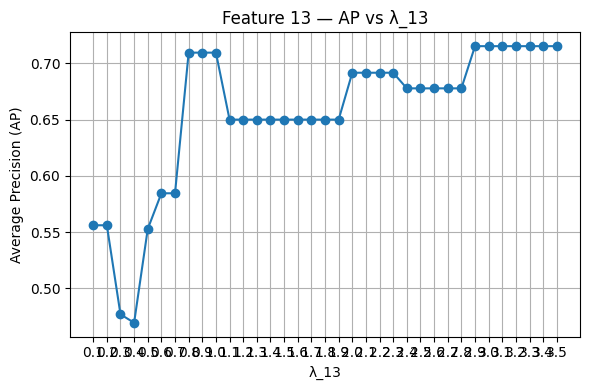

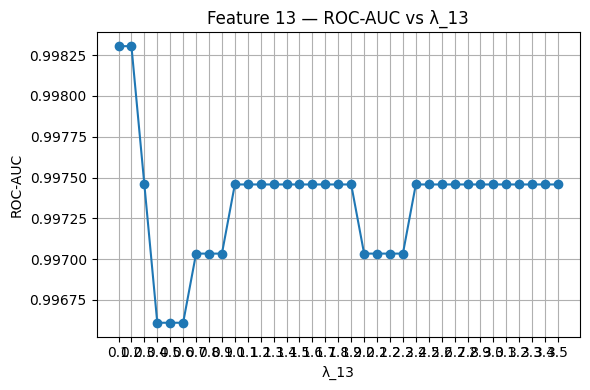

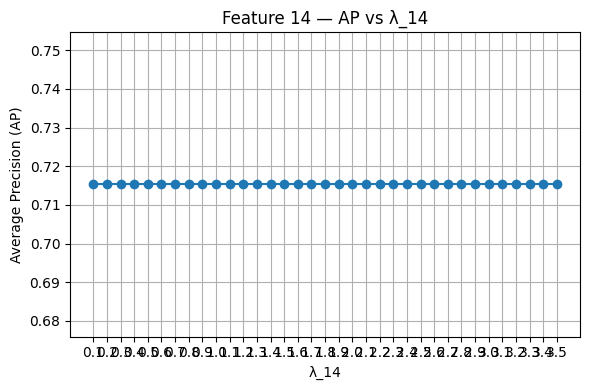

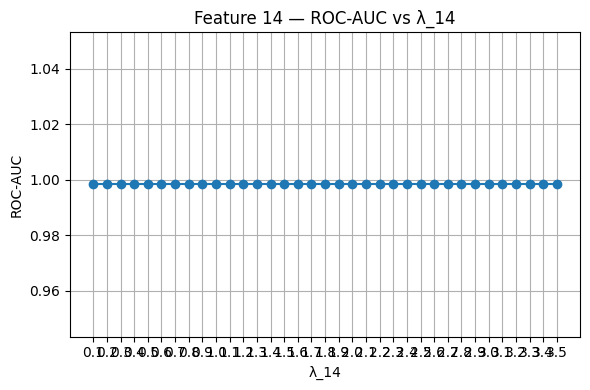

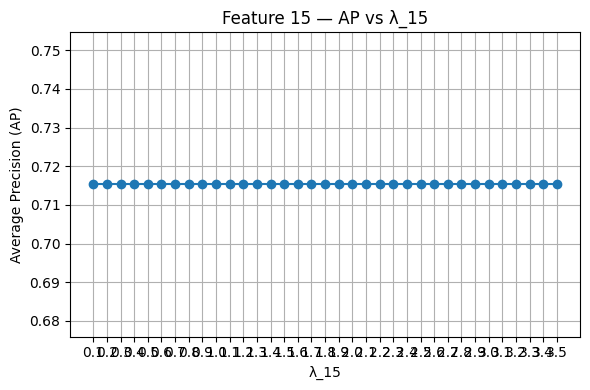

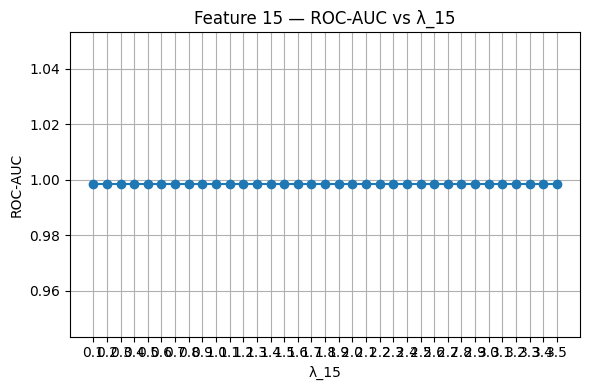

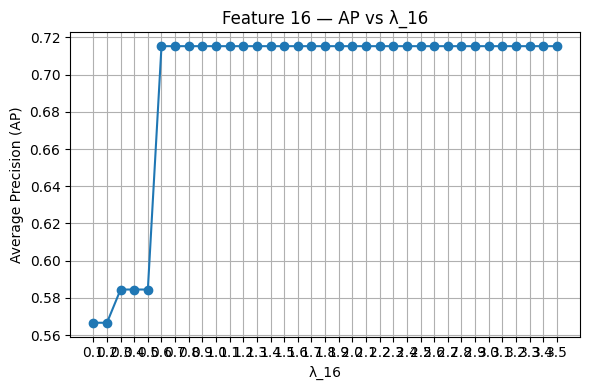

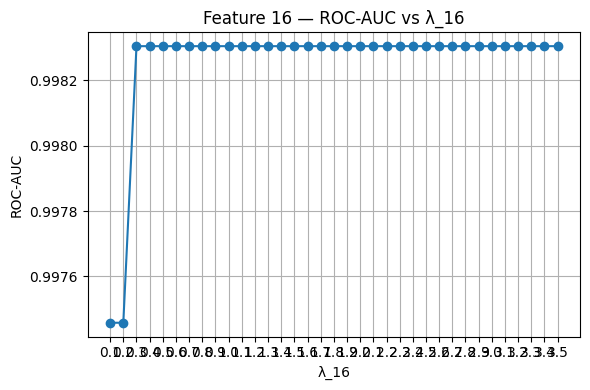

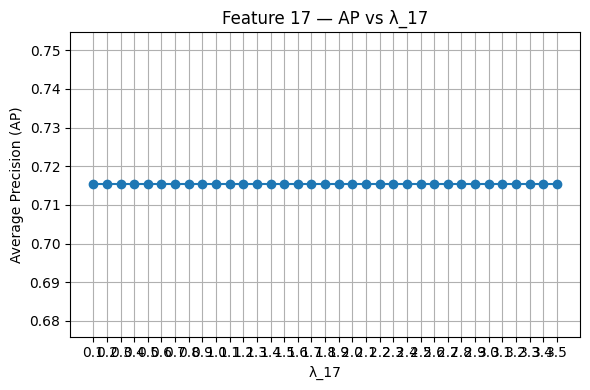

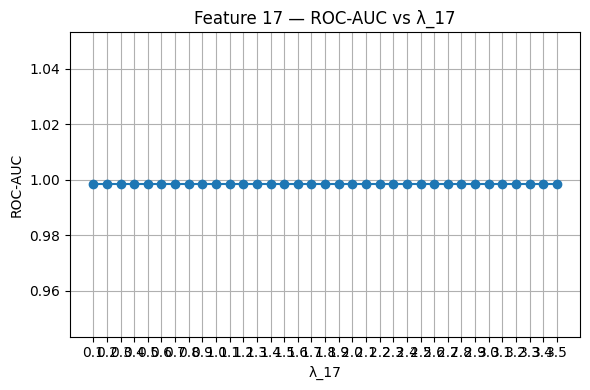

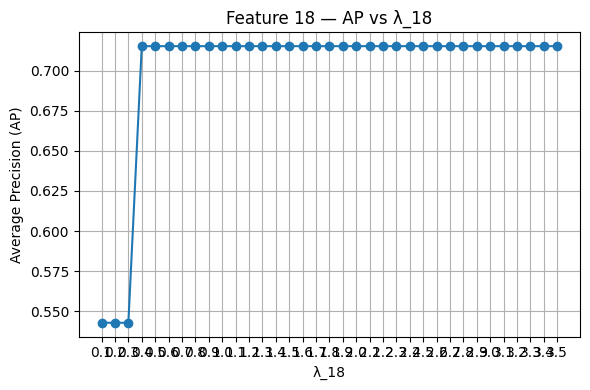

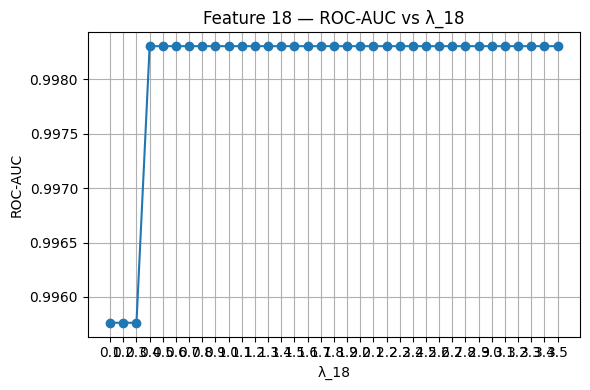

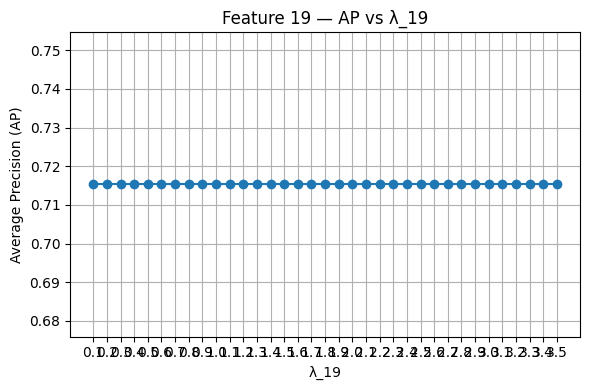

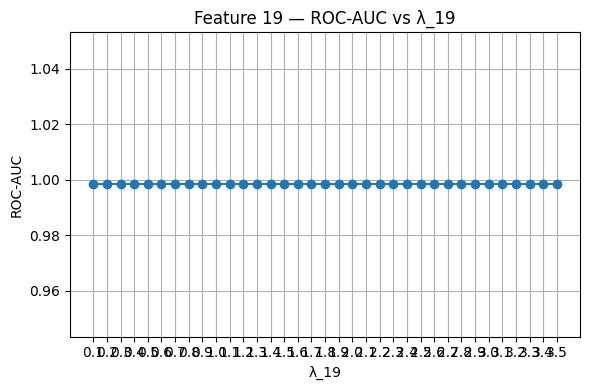

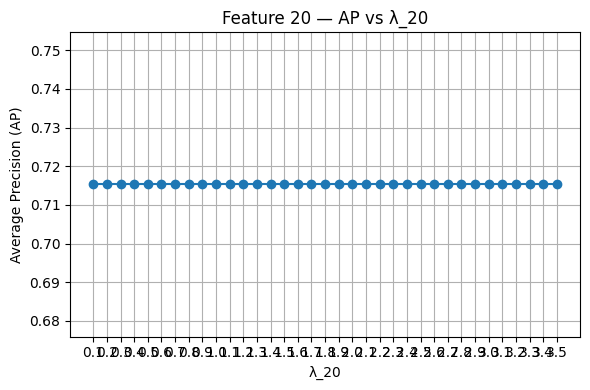

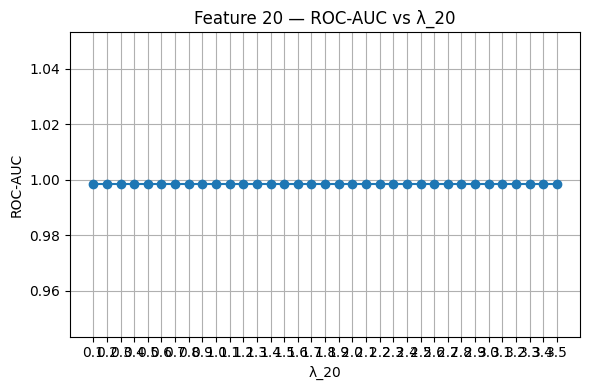

In [29]:
if __name__ == "__main__":
    # =======================
    #1) Setting the parameters
    # =======================
    # List of candidate values for λ
    candidates = [0.1, 0.2, 0.3, 0.4, 0.5,
                  0.6, 0.7, 0.8, 0.9, 1.0,
                  1.1, 1.2, 1.3, 1.4, 1.5,
                  1.6, 1.7, 1.8, 1.9, 2.0,
                  2.1, 2.2, 2.3, 2.4, 2.5,
                  2.6, 2.7, 2.8, 2.9, 3.0,
                  3.1, 3.2, 3.3, 3.4, 3.5]

    # =======================
    #2) Loading and Preprocessing
    # =======================
    mat = loadmat('german_1_14_variant1.mat')
    full_data = mat['trandata']       # shape = (n_samples, 7)
    X33 = full_data[:, :20]                   # First 20 columns
    y33 =  full_data[:, 20].astype(int)       # Column 21 (index 20)

    numeric_idx = [1, 4, 7, 10, 12, 15, 17]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X33[:, numeric_idx] = scaler.fit_transform(X33[:, numeric_idx])

    # ================================
    #3) Greedy search for AP
    # ================================
    best_lams_ap, metrics_ap = greedy_search_lambdas3(
        X33, y33, X_tem3, candidates, metric_name3='AP'
    )
    print("=== Best Lambdas for AP ===")
    print(best_lams_ap)

    # ================================
    #4) Greedy search for ROC-AUC
    # ================================
    best_lams_roc, metrics_roc = greedy_search_lambdas3(
        X33, y33, X_tem3, candidates, metric_name3='ROC'
    )
    print("=== Best Lambdas for ROC-AUC ===")
    print(best_lams_roc)

    # ============================================
    #5) Draw graphs for each feature and each criterion
    # ============================================
    m = X33.shape[1]
    for j in range(m):
        # Chart for AP
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_ap[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — AP vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("Average Precision (AP)")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

        # Chart for ROC-AUC
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_roc[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — ROC-AUC vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("ROC-AUC")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()